# Real-World Dataset Analysis Project
### What distinguishes malignant from benign breast tumours? An exploratory analysis of the Breast Cancer Wisconsin (Diagnostic) dataset

**Author:** Dhanireddy Venu Madhav Reddy  
**Tools:** Python · Jupyter Notebook · NumPy · Pandas · Matplotlib · Seaborn · SciPy · Scikit-learn

> **Educational analysis only.** This project practises data-analysis skills on a public research dataset. Nothing here is medical advice, and the models are **not** diagnostic tools.

---

## Project roadmap
| # | Project objective | Where it is done |
|---|---|---|
| 1 | Select a real-world dataset and understand its context | Section 1 |
| 2 | Explore the dataset | Section 2 |
| 3 | Clean and preprocess the data | Section 3 |
| 4 | Perform exploratory data analysis | Section 4 |
| 5 | Create data visualizations | Section 5 (15 charts) |
| 6 | Present insights and interpretations | Section 6 |

Every step follows the pattern **question → code → output → observation**, and the observations are computed from the results so they always match the numbers shown.

---
# 1. Dataset Selection and Context

## 1.1 Why this dataset?
| Selection criterion | How the dataset meets it |
|---|---|
| **Real-world data** | Measurements from real patients, not simulated or generated data |
| **Reliable, documented source** | UCI Machine Learning Repository; created by researchers at the University of Wisconsin and described in a peer-reviewed conference paper |
| **Suitable size and richness** | 569 records and 30 numeric measurements: large enough for statistics, small enough to explore thoroughly |
| **Clear analytical question** | A well-defined outcome (malignant or benign) that the measurements can be compared against |
| **Openly available** | Freely distributed for research and teaching; a copy ships with scikit-learn, so the project runs offline |
| **Ethically suitable** | Contains no names, identifiers or personal details |

## 1.2 Source details
| Item | Detail |
|---|---|
| Name | Breast Cancer Wisconsin (Diagnostic), "WDBC" |
| Repository | UCI Machine Learning Repository |
| Creators | Dr. William H. Wolberg, W. Nick Street and Olvi L. Mangasarian (University of Wisconsin); donor: Nick Street; donated November 1995 |
| Key reference | W.N. Street, W.H. Wolberg and O.L. Mangasarian, *Nuclear feature extraction for breast tumor diagnosis*, IS&T/SPIE 1993 International Symposium on Electronic Imaging, vol. 1905, pp. 861-870 |
| How it was obtained here | Unmodified copy bundled with scikit-learn (`load_breast_cancer`), exported by `src/prepare_dataset.py` to `data/raw/wdbc_raw.csv` |
| Size | 569 patients x 30 numeric features + 1 class label |
| Class distribution (as documented) | 212 malignant, 357 benign |

## 1.3 Business and analytical context
A **fine needle aspirate (FNA)** is a minimally invasive procedure in which a thin needle removes a few cells from a breast lump. The sample is photographed under a microscope, the image is digitized, and software outlines each **cell nucleus** and measures its shape. A pathologist then decides whether the lump is **malignant** (cancerous) or **benign** (not cancerous).

The analytical value of this dataset is to understand **which nucleus measurements differ between malignant and benign samples, how strongly, and whether the measurements alone are enough to separate the two groups.** Insights of this kind support research on computer-assisted screening, where a model could flag cases for closer human review.

## 1.4 Variables
For each image, **ten characteristics of the cell nuclei** were measured, and each was summarized in **three ways**, giving 10 x 3 = 30 features:

| Characteristic | Meaning |
|---|---|
| radius | Mean distance from the centre of the nucleus to points on its boundary |
| texture | Standard deviation of gray-scale values (variation in brightness) |
| perimeter | Length of the nucleus boundary |
| area | Area of the nucleus |
| smoothness | Local variation in radius lengths |
| compactness | perimeter² / area - 1.0 |
| concavity | Severity of the concave (inward) portions of the boundary |
| concave points | Number of concave portions of the boundary |
| symmetry | Symmetry of the nucleus |
| fractal dimension | "Coastline approximation" - 1; a measure of boundary roughness |

| Summary | Prefix / suffix | Meaning |
|---|---|---|
| Mean | `mean_` | Average over all nuclei in the image |
| Standard error | `_error` | Variability of the measurement across nuclei |
| Worst | `worst_` | Mean of the three largest values (the most extreme nuclei) |

The **class label** (`target` in the raw file) is the diagnosis: malignant or benign.

## 1.5 Analytical objectives and expected outcomes
**Questions to answer**
1. How balanced are the two classes?
2. Which measurements differ most between malignant and benign tumours, and how large are the differences?
3. How are the 30 measurements related to one another? Is there redundancy?
4. Are there outliers, and should they be removed?
5. How well can the measurements separate the two classes?

**Hypotheses stated before looking at the results** (so they can be fairly tested later)
- **H1:** Malignant nuclei are larger (radius, perimeter, area) than benign ones.
- **H2:** Malignant nuclei have more irregular boundaries (higher concavity and concave points).
- **H3:** The size measurements (radius, perimeter, area) are almost perfectly correlated with each other.

**Expected outcome:** a clear, evidence-based description of how the two groups differ, plus an honest assessment of the data's limits.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report, roc_curve
from sklearn.decomposition import PCA

# Seaborn 0.13 + Matplotlib 3.10 print a harmless deprecation notice for box plots; hide only that message
warnings.filterwarnings("ignore", message="vert: bool will be deprecated")

SEED = 42
PAL = {"Malignant": "#C0392B", "Benign": "#2E86AB"}      # one colour per class, used in every chart
ORDER = ["Malignant", "Benign"]

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
RAW_DIR, PROC_DIR, FIG_DIR = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "outputs" / "figures"
for folder in (PROC_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current Matplotlib figure into outputs/figures."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print("Libraries imported. Project folder:", ROOT.name)

Libraries imported. Project folder: lab3


---
# 2. Data Exploration

The goal of this section is to understand the data **as it arrives**, before changing anything: its structure, types, distributions, missing values, duplicates and first relationships.

### Exercise 2.1 – Load the raw data and inspect its structure

In [2]:
raw = pd.read_csv(RAW_DIR / "wdbc_raw.csv")
print(f"Rows: {raw.shape[0]}   Columns: {raw.shape[1]}")
print("First five rows, transposed so that all 31 columns are readable (rows = columns of the data):")
raw.head().T

Rows: 569   Columns: 31
First five rows, transposed so that all 31 columns are readable (rows = columns of the data):


,0,1,2,3,4
mean radius,17.99,20.57,19.69,11.42,20.29
mean texture,10.38,17.77,21.25,20.38,14.34
mean perimeter,122.8,132.9,130,77.58,135.1
mean area,"1,001","1,326","1,203",386.1,"1,297"
mean smoothness,0.1184,0.08474,0.1096,0.1425,0.1003
mean compactness,0.2776,0.07864,0.1599,0.2839,0.1328
mean concavity,0.3001,0.0869,0.1974,0.2414,0.198
mean concave points,0.1471,0.07017,0.1279,0.1052,0.1043
mean symmetry,0.2419,0.1812,0.2069,0.2597,0.1809
mean fractal dimension,0.07871,0.05667,0.05999,0.09744,0.05883


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

**Observation.** The raw table has **569 rows and 31 columns**: 30 numeric features (`float64`) and one integer column, `target`. There are **no text columns**, and the `non-null` count equals the number of rows for every column, which is the first sign that nothing is missing. The column names contain **spaces** (for example `mean radius`), which is inconvenient in code and will be fixed in Section 3.

### Exercise 2.2 – Summary statistics of every column

In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569,14.13,3.524,6.981,11.7,13.37,15.78,28.11
mean texture,569,19.29,4.301,9.71,16.17,18.84,21.8,39.28
mean perimeter,569,91.97,24.3,43.79,75.17,86.24,104.1,188.5
mean area,569,654.9,351.9,143.5,420.3,551.1,782.7,"2,501"
mean smoothness,569,0.09636,0.01406,0.05263,0.08637,0.09587,0.1053,0.1634
mean compactness,569,0.1043,0.05281,0.01938,0.06492,0.09263,0.1304,0.3454
mean concavity,569,0.0888,0.07972,0,0.02956,0.06154,0.1307,0.4268
mean concave points,569,0.04892,0.0388,0,0.02031,0.0335,0.074,0.2012
mean symmetry,569,0.1812,0.02741,0.106,0.1619,0.1792,0.1957,0.304
mean fractal dimension,569,0.0628,0.00706,0.04996,0.0577,0.06154,0.06612,0.09744


**Observation.** The features live on **very different scales**: `mean area` ranges from 144 to 2,501, while `mean smoothness` ranges only from 0.053 to 0.163. For many features the mean is clearly larger than the median (50%), a sign of **right-skewed** distributions with a few very large values (for example `area error`: mean 40.3 vs median 24.5). Both points (scale differences and skewness) will matter for preprocessing.

### Exercise 2.3 – The target variable: class balance and coding

In [5]:
counts = raw["target"].value_counts().sort_index()
print("Raw target values:")
print(counts.to_string())
print(f"\nShare of target = 0: {counts[0] / counts.sum() * 100:.1f}%   |   target = 1: {counts[1] / counts.sum() * 100:.1f}%")

# The documentation states 212 malignant and 357 benign -> check which code is which
assert (raw["target"] == 0).sum() == 212 and (raw["target"] == 1).sum() == 357
print("\nThe counts match the documentation (212 malignant, 357 benign), so  0 = malignant  and  1 = benign.")

Raw target values:
target
0    212
1    357

Share of target = 0: 37.3%   |   target = 1: 62.7%

The counts match the documentation (212 malignant, 357 benign), so  0 = malignant  and  1 = benign.


**Observation.** The classes are moderately imbalanced: **357 benign (1)** versus **212 malignant (0)**. The count of 212 for `target = 0` matches the 212 malignant cases in the documentation, so the coding is **0 = malignant, 1 = benign**. This is the *opposite* of what most people expect ("1 = the condition of interest"), and a classic source of mistakes: an unwary analyst would read a positive correlation with `target` as "more likely malignant" when it actually means "more likely benign". The label will be recoded explicitly in Section 3.

### Exercise 2.4 – Missing values, duplicates and impossible values

In [6]:
audit = pd.DataFrame({
    "dtype":     raw.dtypes.astype(str),
    "missing":   raw.isna().sum(),
    "zeros":     (raw == 0).sum(),
    "negatives": (raw < 0).sum(),
    "unique":    raw.nunique(),
})
print("Total missing cells        :", int(raw.isna().sum().sum()))
print("Fully duplicated rows      :", int(raw.duplicated().sum()))
print("Duplicated feature vectors :", int(raw.drop(columns="target").duplicated().sum()))
print("Negative values (all cols) :", int((raw < 0).sum().sum()))
print("Columns by data type       :", audit["dtype"].value_counts().to_dict())

print("\nColumns containing zeros (a zero is suspicious for a physical measurement):")
audit[audit["zeros"] > 0]

Total missing cells        : 0
Fully duplicated rows      : 0
Duplicated feature vectors : 0
Negative values (all cols) : 0
Columns by data type       : {'float64': 30, 'int64': 1}

Columns containing zeros (a zero is suspicious for a physical measurement):


,dtype,missing,zeros,negatives,unique
mean concavity,float64,0,13,0,537
mean concave points,float64,0,13,0,542
concavity error,float64,0,13,0,533
concave points error,float64,0,13,0,507
worst concavity,float64,0,13,0,539
worst concave points,float64,0,13,0,492
target,int64,0,212,0,2


**Observation.** The audit is clean on the usual problems: **0 missing cells, 0 duplicate rows, 0 negative values**, and every feature has the correct numeric type. This is expected for a **curated research dataset** that was cleaned by its creators, so these checks come back clean rather than revealing problems; reporting that honestly is part of the analysis.

The audit does reveal one unusual feature: **six columns contain zeros** (`concavity` and `concave points`, in their mean, error and worst forms), always **13 times**, suggesting the same rows are involved. A truly zero measurement needs explaining, so it is investigated in Section 3.

### Exercise 2.5 – Do the measurements behave like real geometry?
Radius, perimeter and area describe the *same* outline. For a circle, area = π·r² and perimeter = 2π·r. Real nuclei are not perfect circles, but the ratios should stay close to 1. If they do not, there may be unit or entry errors.

In [7]:
area_ratio  = raw["mean area"] / (np.pi * raw["mean radius"] ** 2)
perim_ratio = raw["mean perimeter"] / (2 * np.pi * raw["mean radius"])
geometry = pd.DataFrame({"area / (pi * r^2)": area_ratio, "perimeter / (2 * pi * r)": perim_ratio}).describe().loc[["min", "25%", "50%", "75%", "max"]]
geometry

,area / (pi * r^2),perimeter / (2 * pi * r)
min,0.917,0.9828
25%,0.9724,1.017
50%,0.981,1.03
75%,0.9879,1.044
max,1.064,1.133


**Observation.** Both ratios stay close to 1: the area ratio lies between **0.92 and 1.06** and the perimeter ratio between **0.98 and 1.13**. The perimeter ratio is never below 1 by more than 0.02, as expected because irregular outlines are longer than a circle's. So the three size measurements are **internally consistent** and there is no sign of unit mix-ups or typing errors. A domain-knowledge check like this is a useful complement to purely statistical checks.

### Exercise 2.6 – A first look at relationships and distribution shape

In [8]:
feat_raw = [c for c in raw.columns if c != "target"]
first_look = pd.DataFrame({
    "skewness": raw[feat_raw].skew(),
    "corr_with_target": raw[feat_raw].corrwith(raw["target"]),
}).sort_values("corr_with_target")

print("Most NEGATIVE correlation with target (remember: target 0 = malignant):")
display(first_look.head(5))
print("Weakest correlation with target:")
display(first_look.reindex(first_look["corr_with_target"].abs().sort_values().index).head(3))
print(f"Features with |skewness| > 1: {(first_look['skewness'].abs() > 1).sum()} of {len(first_look)}")

Most NEGATIVE correlation with target (remember: target 0 = malignant):


,skewness,corr_with_target
worst concave points,0.4926,-0.7936
worst perimeter,1.128,-0.7829
mean concave points,1.171,-0.7766
worst radius,1.103,-0.7765
mean perimeter,0.9907,-0.7426


Weakest correlation with target:


,skewness,corr_with_target
symmetry error,2.195,0.006522
texture error,1.646,0.008303
mean fractal dimension,1.304,0.01284


Features with |skewness| > 1: 22 of 30


**Observation.** The strongest correlations with `target` are all **negative** (as low as -0.79) and belong to the size and concavity features. Because `target = 0` means malignant, a negative correlation means *higher values go with malignancy*. The weakest relationships are for `symmetry error` (r = 0.007), so not every measurement is useful. Also, **22 of 30 features are noticeably skewed**. These first impressions are tested properly in Section 4.

---
# 3. Data Cleaning and Preprocessing

Because the source is already curated, the cleaning task is mainly **verifying quality and preparing the data for analysis**, not repairing damage. Each decision below is explained, because a wrong cleaning decision (for example deleting "outliers" that carry real information) can quietly damage the results.

**Process:** make a working copy → fix names and labels → verify types → investigate zeros → investigate outliers → handle skewness → handle redundancy → scale → validate and save.

### Exercise 3.1 – Standardize column names and recode the target

In [9]:
df = raw.copy()                                                      # the raw data stays untouched

df.columns = df.columns.str.strip().str.replace(" ", "_").str.lower()   # 'mean radius' -> 'mean_radius'
df["diagnosis"]    = df["target"].map({0: "Malignant", 1: "Benign"}).astype("category")
df["is_malignant"] = (df["target"] == 0).astype(int)                 # 1 = malignant (the intuitive direction)
df = df.drop(columns="target")

FEATURES = [c for c in df.columns if c not in ("diagnosis", "is_malignant")]
BASES = ["radius", "texture", "perimeter", "area", "smoothness", "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
MEAN  = [f"mean_{b}"  for b in BASES]
SE    = [f"{b}_error" for b in BASES]
WORST = [f"worst_{b}" for b in BASES]
assert sorted(MEAN + SE + WORST) == sorted(FEATURES), "feature groups do not cover all columns"

print("Example column names :", FEATURES[:3], "...")
print("Feature groups        :", len(MEAN), "mean +", len(SE), "error +", len(WORST), "worst =", len(FEATURES))
print()
print(df["diagnosis"].value_counts().to_string())
df[["diagnosis", "is_malignant", "mean_radius", "mean_concave_points", "worst_perimeter"]].head()

Example column names : ['mean_radius', 'mean_texture', 'mean_perimeter'] ...
Feature groups        : 10 mean + 10 error + 10 worst = 30

diagnosis
Benign       357
Malignant    212


,diagnosis,is_malignant,mean_radius,mean_concave_points,worst_perimeter
0,Malignant,1,17.99,0.1471,184.6
1,Malignant,1,20.57,0.07017,158.8
2,Malignant,1,19.69,0.1279,152.5
3,Malignant,1,11.42,0.1052,98.87
4,Malignant,1,20.29,0.1043,152.2


**Observation.** Column names are now lower-case with underscores, so they can be used in code and formulas without quotes or spaces. The cryptic `target` is replaced by a readable `diagnosis` category (**Malignant / Benign**) and an unambiguous `is_malignant` flag where **1 = malignant**. The assertion proves that the three feature groups (mean, error, worst) cover all 30 columns exactly once, and the counts (212 malignant, 357 benign) are unchanged.

### Exercise 3.2 – Verify data types

In [10]:
print("Feature dtypes       :", df[FEATURES].dtypes.astype(str).unique().tolist())
print("diagnosis dtype      :", df["diagnosis"].dtype, "| categories:", list(df["diagnosis"].cat.categories))
print("is_malignant dtype   :", df["is_malignant"].dtype)
print("Memory use           :", f"{df.memory_usage(deep=True).sum() / 1024:.0f} KB")

Feature dtypes       : ['float64']
diagnosis dtype      : category | categories: ['Benign', 'Malignant']
is_malignant dtype   : int64
Memory use           : 139 KB


**Observation.** All 30 features are `float64`, which is correct for continuous measurements; `diagnosis` is a `category` (efficient and prevents typos) and `is_malignant` is an integer flag. No type conversion is needed. The whole table needs only about 139 KB, so no memory optimization is necessary.

### Exercise 3.3 – Investigate the suspicious zeros

In [11]:
zero_cols = [c for c in FEATURES if (df[c] == 0).any()]
zero_matrix = df[zero_cols] == 0
rows_with_zero = zero_matrix.any(axis=1)

print("Columns with zeros   :", zero_cols)
print("Rows with a zero     :", int(rows_with_zero.sum()))
print("Are they the SAME rows in all six columns?", bool(zero_matrix.sum(axis=1).isin([0, len(zero_cols)]).all()))
print("\nDiagnosis of these rows:")
print(df.loc[rows_with_zero, "diagnosis"].value_counts().to_string())
print("\nTheir mean_radius vs the rest:", round(df.loc[rows_with_zero, "mean_radius"].mean(), 2), "vs", round(df.loc[~rows_with_zero, "mean_radius"].mean(), 2))

Columns with zeros   : ['mean_concavity', 'mean_concave_points', 'concavity_error', 'concave_points_error', 'worst_concavity', 'worst_concave_points']
Rows with a zero     : 13
Are they the SAME rows in all six columns? True

Diagnosis of these rows:
diagnosis
Benign       13
Malignant     0

Their mean_radius vs the rest: 9.41 vs 14.24


**Observation.** The zeros come from just **13 rows**, and the *same* rows have zero in all six columns, so this is one coherent group, not scattered errors. **All of them are benign.** A nucleus with a smooth, round outline has no inward-curving (concave) parts, so `concavity = 0` and `concave points = 0` are **genuinely meaningful values, not missing data coded as zero**. Replacing them with an average would be a mistake. Decision: **keep the zeros**. They are also informative: a measured concavity of exactly zero never occurs in a malignant sample here.

### Exercise 3.4 – Investigate outliers (and decide whether to remove them)
The IQR rule flags a value as an outlier when it lies more than 1.5 x IQR beyond the quartiles. Flagging is only the first step; the real question is **are these values errors, or real?**

In [12]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

out_mask = df[FEATURES].apply(iqr_outliers)
outlier_summary = pd.DataFrame({
    "outliers": out_mask.sum(),
    "malignant_share_%": [df.loc[out_mask[c], "is_malignant"].mean() * 100 if out_mask[c].any() else np.nan for c in FEATURES],
}).sort_values("outliers", ascending=False)
display(outlier_summary.head(8))

any_outlier = out_mask.any(axis=1)
print(f"Rows with at least one outlier value : {any_outlier.sum()} of {len(df)} ({any_outlier.mean() * 100:.1f}%)")
print(f"Malignant share among those rows     : {df.loc[any_outlier, 'is_malignant'].mean() * 100:.1f}%  (overall: {df['is_malignant'].mean() * 100:.1f}%)")

# Outliers judged only against the patient's OWN class
print("\nOutliers in area_error, judged against ALL patients vs within each class:")
print("  all patients:", int(iqr_outliers(df["area_error"]).sum()))
print("  within class:", df.groupby("diagnosis", observed=True)["area_error"].apply(lambda s: int(iqr_outliers(s).sum())).to_dict())

,outliers,malignant_share_%
area_error,65,100
radius_error,38,97.37
perimeter_error,38,100
worst_area,35,100
smoothness_error,30,13.33
fractal_dimension_error,28,35.71
compactness_error,28,50
symmetry_error,27,59.26


Rows with at least one outlier value : 171 of 569 (30.1%)
Malignant share among those rows     : 66.7%  (overall: 37.3%)

Outliers in area_error, judged against ALL patients vs within each class:
  all patients: 65
  within class: {'Benign': 15, 'Malignant': 5}


**Observation.** The IQR rule flags **608 individual values** in **171 rows (30.1% of patients)**. The pattern is decisive: the features with the most outliers (`area_error`, `radius_error`, `perimeter_error`) have outliers that are **100%, 97% and 100% malignant**, and malignant patients make up 66.7% of all flagged rows against 37.3% of the dataset. Judged within their own class, the number of `area_error` outliers drops from 65 to 20.

**Decision: keep all outliers.** They are not data-entry errors (the geometry check in Exercise 2.5 found none); they are **large, genuinely abnormal tumours**, which is exactly the signal we want to study. Deleting them would remove the most informative malignant cases and bias every later result. The lesson: *an outlier is a question, not an answer.* Methods that are sensitive to extremes (such as the mean) will be complemented by robust ones (the median, rank-based tests).

### Exercise 3.5 – Reduce skewness with a log transform

In [13]:
skew = df[FEATURES].skew()
skewed = skew[skew.abs() > 1].index.tolist()

df_log = df.copy()
df_log[skewed] = np.log1p(df_log[skewed])            # log(1 + x): safe even for the zero values found above

skew_cmp = pd.DataFrame({"skew_before": skew[skewed], "skew_after_log1p": df_log[skewed].skew()}).sort_values("skew_before", ascending=False)
print(f"Features with |skewness| > 1 before: {len(skewed)}")
print(f"Features with |skewness| > 1 after : {int((df_log[FEATURES].skew().abs() > 1).sum())}")
skew_cmp.head(8)

Features with |skewness| > 1 before: 22
Features with |skewness| > 1 after : 15


,skew_before,skew_after_log1p
area_error,5.447,0.8473
concavity_error,5.11,4.232
fractal_dimension_error,3.924,3.874
perimeter_error,3.444,1.025
radius_error,3.089,1.713
smoothness_error,2.314,2.283
symmetry_error,2.195,2.136
compactness_error,1.902,1.816


**Observation.** **22 of 30 features** were strongly skewed (|skewness| > 1) and the transform reduced that number to **15**. The effect is very uneven: it works well where the skew comes from a long tail of large values (`area_error`: 5.45 down to 0.85; `perimeter_error`: 3.44 down to 1.03) but barely helps others (`concavity_error`: 5.11 to 4.23), whose values are crowded near zero. So **a single transform is not a cure-all**; alternatives such as Yeo-Johnson, or rank-based methods that do not need symmetry (used in Section 4), are available. The transformed copy `df_log` is kept **separately**, so the original units remain available for interpretation. `log1p` was chosen over `log` because several columns contain exact zeros.

### Exercise 3.6 – Detect redundancy (multicollinearity)

In [14]:
corr_abs = df[FEATURES].corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
pairs = upper.stack().rename("abs_r").reset_index()
pairs.columns = ["feature_1", "feature_2", "abs_r"]
high = pairs[pairs["abs_r"] > 0.90].sort_values("abs_r", ascending=False)
print(f"Feature pairs with |r| > 0.90: {len(high)} of {len(pairs)} possible pairs")
display(high.head(8))

# Greedy selection: keep a feature only if it is not highly correlated with one already kept
REDUCED = []
for f in FEATURES:
    if all(corr_abs.loc[f, k] <= 0.90 for k in REDUCED):
        REDUCED.append(f)
print(f"\nFeatures kept after removing redundancy (|r| <= 0.90): {len(REDUCED)} of {len(FEATURES)}")
print(REDUCED)

Feature pairs with |r| > 0.90: 21 of 900 possible pairs


,feature_1,feature_2,abs_r
2,mean_radius,mean_perimeter,0.9979
622,worst_radius,worst_perimeter,0.9937
3,mean_radius,mean_area,0.9874
63,mean_perimeter,mean_area,0.9865
623,worst_radius,worst_area,0.984
683,worst_perimeter,worst_area,0.9776
312,radius_error,perimeter_error,0.9728
82,mean_perimeter,worst_perimeter,0.9704



Features kept after removing redundancy (|r| <= 0.90): 21 of 30
['mean_radius', 'mean_texture', 'mean_smoothness', 'mean_compactness', 'mean_concavity', 'mean_symmetry', 'mean_fractal_dimension', 'radius_error', 'texture_error', 'smoothness_error', 'compactness_error', 'concavity_error', 'concave_points_error', 'symmetry_error', 'fractal_dimension_error', 'worst_smoothness', 'worst_compactness', 'worst_concavity', 'worst_concave_points', 'worst_symmetry', 'worst_fractal_dimension']


**Observation.** **21 pairs** of features are correlated above 0.90, and the top of the list is dominated by the size measurements: `mean_radius` and `mean_perimeter` have |r| = **0.998**. This is expected (the radius, perimeter and area describe the same outline) and it supports **hypothesis H3**. The 30 features therefore contain a lot of repeated information. A simple greedy filter keeps **21 less-redundant features** (`REDUCED`); Section 4.5 tests whether this smaller set loses any predictive information.

### Exercise 3.7 – Scale the features

In [15]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(df[FEATURES]), columns=FEATURES, index=df.index)

before = df[FEATURES].std()
print(f"Standard deviations BEFORE scaling: from {before.min():.4f} ({before.idxmin()}) to {before.max():,.1f} ({before.idxmax()})")
print(f"Standard deviations AFTER  scaling: from {X_scaled.std(ddof=0).min():.3f} to {X_scaled.std(ddof=0).max():.3f}")
print(f"Means AFTER scaling: all within +/- {X_scaled.mean().abs().max():.1e} of 0")

Standard deviations BEFORE scaling: from 0.0026 (fractal_dimension_error) to 569.4 (worst_area)
Standard deviations AFTER  scaling: from 1.000 to 1.000
Means AFTER scaling: all within +/- 8.4e-16 of 0


**Observation.** Before scaling, the spread of the features differs by a factor of roughly **220,000** (from 0.0026 to 569.4). Distance-based and regularized methods (PCA, logistic regression) would let large-unit features such as `area` dominate. After standardization every feature has mean 0 and standard deviation 1, making them directly comparable. The scaler is used for PCA and modelling only; the descriptive statistics and charts use the original units, which are easier to interpret.

### Exercise 3.8 – Validate, document the decisions and save

In [16]:
# Automatic validation checks: the cell stops with an error if any rule is broken
assert df.shape == (569, 32)
assert df[FEATURES].notna().all().all()
assert not df.duplicated().any()
assert (df[FEATURES] >= 0).all().all()
assert set(df["diagnosis"].unique()) == {"Malignant", "Benign"}
assert (df["is_malignant"] == (df["diagnosis"] == "Malignant").astype(int)).all()
assert np.allclose(X_scaled.mean(), 0, atol=1e-9) and np.allclose(X_scaled.std(ddof=0), 1)
print("All validation checks passed.\n")

decision_log = pd.DataFrame([
    ("Missing values",        f"{int(raw.isna().sum().sum())} found",                        "None needed"),
    ("Duplicate rows",        f"{int(raw.duplicated().sum())} found",                        "None needed"),
    ("Column names",          "Contain spaces",                                              "Converted to snake_case"),
    ("Target coding",         "0 = malignant (counter-intuitive)",                           "Recoded to diagnosis + is_malignant (1 = malignant)"),
    ("Data types",            "All correct",                                                 "Kept; diagnosis stored as category"),
    ("Zero values",           f"{int(rows_with_zero.sum())} rows, 6 columns, all benign",    "Kept (genuine: no concave portions)"),
    ("Outliers (IQR rule)",   f"{int(any_outlier.sum())} rows flagged, mostly malignant",    "Kept (real abnormal tumours, not errors)"),
    ("Skewed features",       f"{len(skewed)} of 30",                                        "log1p copy created (df_log); original kept"),
    ("Redundant features",    f"{len(high)} pairs with |r| > 0.90",                          f"Reduced set of {len(REDUCED)} features defined"),
    ("Different scales",      f"Std range x{before.max() / before.min():,.0f}",               "StandardScaler used for PCA and models"),
], columns=["Check", "Finding", "Action"])
display(decision_log)

df.to_csv(PROC_DIR / "wdbc_clean.csv", index=False)
pd.Series(REDUCED, name="reduced_features").to_csv(PROC_DIR / "reduced_features.csv", index=False)
print("Saved:", [p.name for p in sorted(PROC_DIR.glob("*.csv"))])

All validation checks passed.



,Check,Finding,Action
0,Missing values,0 found,None needed
1,Duplicate rows,0 found,None needed
2,Column names,Contain spaces,Converted to snake_case
3,Target coding,0 = malignant (counter-intuitive),Recoded to diagnosis + is_malignant (1 = malig...
4,Data types,All correct,Kept; diagnosis stored as category
5,Zero values,"13 rows, 6 columns, all benign",Kept (genuine: no concave portions)
6,Outliers (IQR rule),"171 rows flagged, mostly malignant","Kept (real abnormal tumours, not errors)"
7,Skewed features,22 of 30,log1p copy created (df_log); original kept
8,Redundant features,21 pairs with |r| > 0.90,Reduced set of 21 features defined
9,Different scales,"Std range x215,171",StandardScaler used for PCA and models


Saved: ['reduced_features.csv', 'wdbc_clean.csv']


**Observation.** All seven validation checks pass, so the processed data satisfies every rule defined above. The decision log summarizes *what was checked, what was found and what was done*. Recording the reasoning behind each cleaning decision makes the analysis transparent and reproducible, and lets a reader disagree with a specific choice. The cleaned table is saved to `data/processed/wdbc_clean.csv`; the raw file is never modified.

---
# 4. Exploratory Data Analysis (Pandas, NumPy and Statistics)

This section answers the research questions from Section 1.5 with numbers: how the two groups differ, how large the differences are, how the features relate to each other, and whether the measurements can separate the classes.

### Exercise 4.1 – Compare the two groups: means and medians
Both the mean and the median are shown, because the mean is sensitive to the extreme values discussed in Section 3.

In [17]:
mal = df[df["is_malignant"] == 1]
ben = df[df["is_malignant"] == 0]

mean_by = df.groupby("diagnosis", observed=True)[MEAN].mean().T
med_by  = df.groupby("diagnosis", observed=True)[MEAN].median().T
summary = pd.DataFrame({
    "mean_malignant":   mean_by["Malignant"],  "mean_benign":   mean_by["Benign"],
    "median_malignant": med_by["Malignant"],   "median_benign": med_by["Benign"],
})
summary["ratio_M/B"] = summary["mean_malignant"] / summary["mean_benign"]
summary = summary.sort_values("ratio_M/B", ascending=False)
summary

,mean_malignant,mean_benign,median_malignant,median_benign,ratio_M/B
mean_concavity,0.1608,0.04606,0.1513,0.03709,3.491
mean_concave_points,0.08799,0.02572,0.08628,0.02344,3.421
mean_area,978.4,462.8,932,458.4,2.114
mean_compactness,0.1452,0.08008,0.1323,0.07529,1.813
mean_perimeter,115.4,78.08,114.2,78.18,1.478
mean_radius,17.46,12.15,17.33,12.2,1.438
mean_texture,21.6,17.91,21.46,17.39,1.206
mean_smoothness,0.1029,0.09248,0.1022,0.09076,1.113
mean_symmetry,0.1929,0.1742,0.1899,0.1714,1.107
mean_fractal_dimension,0.06268,0.06287,0.06158,0.06154,0.997


**Observation.** Malignant tumours have higher average values for **9 of the ten** mean features. The smallest difference is in `mean_fractal_dimension`, where the groups are practically the same (ratio 1.00). The largest differences are in **`mean_concavity`** (malignant mean **3.5 times** the benign mean), `mean_concave_points` (3.4x) and `mean_area` (2.1x). Size also differs: the average `mean_radius` is 17.5 for malignant versus 12.1 for benign, and the medians tell the same story, so the result does not depend on a few extreme values.

### Exercise 4.2 – How large are the differences? Effect sizes and statistical tests
Two complementary measures are used for each of the 30 features:
- **Cohen's d**: the difference between group means divided by the pooled standard deviation. A common rule of thumb is 0.2 = small, 0.5 = medium, 0.8 = large.
- **Mann-Whitney U test**: a rank-based test that does not assume a normal distribution (the data are skewed), with the **Bonferroni correction** for testing 30 features (significance threshold 0.05 / 30).

A third column gives the **AUC** of the raw feature: the probability that a randomly chosen malignant case has a more extreme value than a randomly chosen benign case (0.5 = no separation, 1.0 = perfect).

In [18]:
def cohens_d(a, b):
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled

rows = []
for f in FEATURES:
    u = stats.mannwhitneyu(mal[f], ben[f], alternative="two-sided")
    auc = roc_auc_score(df["is_malignant"], df[f])
    rows.append({"feature": f, "cohens_d": cohens_d(mal[f], ben[f]), "p_value": u.pvalue, "auc": max(auc, 1 - auc)})

effects = pd.DataFrame(rows).set_index("feature")
effects["abs_d"] = effects["cohens_d"].abs()
effects = effects.sort_values("abs_d", ascending=False)
ALPHA = 0.05 / len(FEATURES)
effects["significant"] = effects["p_value"] < ALPHA

display(effects.head(10))
print(f"Features with a LARGE effect (|d| >= 0.8)            : {(effects['abs_d'] >= 0.8).sum()} of {len(effects)}")
print(f"Significant after Bonferroni (p < {ALPHA:.4f})        : {effects['significant'].sum()} of {len(effects)}")
print("\nWeakest differences:")
display(effects.sort_values("abs_d").head(4))

,cohens_d,p_value,auc,abs_d,significant
feature,,,,,
worst_concave_points,2.693,1.864e-77,0.9667,2.693,True
worst_perimeter,2.598,2.583e-80,0.9755,2.598,True
mean_concave_points,2.545,1.006e-76,0.9644,2.545,True
worst_radius,2.544,1.136e-78,0.9704,2.544,True
mean_perimeter,2.29,3.554e-71,0.9469,2.29,True
worst_area,2.23,1.803e-78,0.9698,2.23,True
mean_radius,2.205,2.693e-68,0.9375,2.205,True
mean_area,2.076,1.54e-68,0.9383,2.076,True
mean_concavity,2.003,2.165e-68,0.9378,2.003,True


Features with a LARGE effect (|d| >= 0.8)            : 20 of 30
Significant after Bonferroni (p < 0.0017)        : 26 of 30

Weakest differences:


,cohens_d,p_value,auc,abs_d,significant
feature,,,,,
symmetry_error,-0.01347,0.02784,0.5551,0.01347,False
texture_error,-0.01714,0.6437,0.5116,0.01714,False
mean_fractal_dimension,-0.02651,0.5372,0.5155,0.02651,False
smoothness_error,-0.1387,0.2136,0.5312,0.1387,False


**Observation.** The differences are large and highly significant for most of the features:
- The top features are **`worst_concave_points`** (d = 2.69), `worst_perimeter` (2.60) and `mean_concave_points` (2.55). A d above 2 means the group averages are more than **two standard deviations apart**, an exceptionally large separation for real data.
- **20 of 30 features** have a large effect, and **26 of 30** remain significant after the Bonferroni correction. The p-values for the top features are astronomically small, yet the effect size (d) is the more informative number, because with 569 patients even tiny differences can be "significant".
- The AUC of the single best raw feature, `worst_perimeter`, is **0.975**: just one measurement ranks a random malignant case above a random benign one about 98% of the time.
- **Not every feature matters:** `symmetry_error` (d = -0.01), `texture_error` and `mean_fractal_dimension` show almost no difference between the groups.

**Hypotheses H1 and H2.** Nucleus size is clearly larger in malignant tumours (`mean_radius` d = 2.21, `mean_area` d = 2.08), so **H1 is supported**. Boundary irregularity is also clearly larger (`mean_concave_points` d = 2.55, `mean_concavity` d = 2.00), so **H2 is supported**.

### Exercise 4.3 – How do the features relate to each other?

In [19]:
pairs_of_interest = [
    ("mean_radius", "mean_perimeter"), ("mean_radius", "mean_area"),
    ("mean_concavity", "mean_concave_points"), ("mean_compactness", "mean_concavity"),
    ("mean_radius", "mean_texture"), ("mean_radius", "mean_fractal_dimension"),
]
rel = pd.DataFrame({"pearson_r": [df[a].corr(df[b]) for a, b in pairs_of_interest],
                    "spearman_rho": [df[a].corr(df[b], method="spearman") for a, b in pairs_of_interest]},
                   index=[f"{a} vs {b}" for a, b in pairs_of_interest])
display(rel)

cm_mean = df[MEAN].corr()
size_block = cm_mean.loc[["mean_radius", "mean_perimeter", "mean_area"], ["mean_radius", "mean_perimeter", "mean_area"]]
mean_size_r = size_block.values[np.triu_indices(3, k=1)].mean()
print(f"Average correlation inside the size block (radius, perimeter, area): {mean_size_r:.3f}")
irr = df[["mean_compactness", "mean_concavity", "mean_concave_points"]].corr().values[np.triu_indices(3, k=1)]
print(f"Correlations inside the irregularity block (compactness, concavity, concave points): {irr.min():.2f} to {irr.max():.2f}")

,pearson_r,spearman_rho
mean_radius vs mean_perimeter,0.9979,0.9978
mean_radius vs mean_area,0.9874,0.9996
mean_concavity vs mean_concave_points,0.9214,0.9274
mean_compactness vs mean_concavity,0.8831,0.8965
mean_radius vs mean_texture,0.3238,0.341
mean_radius vs mean_fractal_dimension,-0.3116,-0.3499


Average correlation inside the size block (radius, perimeter, area): 0.991
Correlations inside the irregularity block (compactness, concavity, concave points): 0.83 to 0.92


**Observation.** Three kinds of relationship appear:
1. **Near-perfect redundancy:** radius and perimeter (r = **0.998**) and radius and area (r = **0.987**) are almost the same variable measured differently. This confirms **hypothesis H3**; the average correlation inside the size block is 0.991.
2. **Strong but not identical:** concavity and concave points (r = 0.92) and compactness and concavity (r = 0.88) move together because they describe related aspects of boundary irregularity.
3. **Nearly independent:** radius versus texture (r = 0.32) shows that brightness variation carries information that size does not.

Pearson and Spearman agree closely, so these relationships are not caused by a few extreme points.

### Exercise 4.4 – Trends: how does the chance of malignancy change with size?
Patients are grouped into **ten equal-sized bands (deciles)** of `worst_perimeter`, and the share of malignant cases is calculated in each band.

In [20]:
df["worst_perimeter_decile"] = pd.qcut(df["worst_perimeter"], 10, labels=[f"D{i}" for i in range(1, 11)])
trend = df.groupby("worst_perimeter_decile", observed=True).agg(
    patients=("is_malignant", "size"),
    malignant_rate_pct=("is_malignant", lambda s: s.mean() * 100),
    min_worst_perimeter=("worst_perimeter", "min"),
    max_worst_perimeter=("worst_perimeter", "max"),
)
display(trend)

ben_max, mal_min = ben["worst_perimeter"].max(), mal["worst_perimeter"].min()
overlap_n = int(((df["worst_perimeter"] >= mal_min) & (df["worst_perimeter"] <= ben_max)).sum())
mixed = trend[(trend["malignant_rate_pct"] > 10) & (trend["malignant_rate_pct"] < 90)]
mixed_n = int(mixed["patients"].sum())
mixed_lo, mixed_hi = mixed["min_worst_perimeter"].min(), mixed["max_worst_perimeter"].max()
print(f"Bands where the diagnosis is genuinely mixed (malignant share between 10% and 90%): {', '.join(mixed.index)}")
print(f"  -> worst_perimeter from {mixed_lo:.1f} to {mixed_hi:.1f}, containing {mixed_n} patients ({mixed_n / len(df) * 100:.1f}%)")
print(f"Largest benign worst_perimeter  : {ben_max:.1f}")
print(f"Smallest malignant worst_perimeter: {mal_min:.1f}")
print(f"Patients between those two extremes [{mal_min:.1f}, {ben_max:.1f}]: {overlap_n} of {len(df)} ({overlap_n / len(df) * 100:.1f}%)")

# Same idea with a different feature: quartiles of mean_concave_points
q_trend = df.groupby(pd.qcut(df["mean_concave_points"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]), observed=True)["is_malignant"].mean().mul(100)
print("\nMalignant rate (%) by quartile of mean_concave_points:")
print(q_trend.round(1).to_string())

,patients,malignant_rate_pct,min_worst_perimeter,max_worst_perimeter
worst_perimeter_decile,,,,
D1,57,0,50.41,72.01
D2,57,0,72.22,81.39
D3,57,1.754,81.41,86.26
D4,57,1.754,86.43,91.29
D5,57,8.772,91.36,97.66
D6,56,17.86,97.67,105.5
D7,58,48.28,105.8,115.9
D8,57,94.74,116.2,133.5
D9,56,100,134.9,157.6


Bands where the diagnosis is genuinely mixed (malignant share between 10% and 90%): D6, D7
  -> worst_perimeter from 97.7 to 115.9, containing 114 patients (20.0%)
Largest benign worst_perimeter  : 127.1
Smallest malignant worst_perimeter: 85.1
Patients between those two extremes [85.1, 127.1]: 275 of 569 (48.3%)

Malignant rate (%) by quartile of mean_concave_points:
mean_concave_points
Q1 (lowest)     0.7
Q2                7
Q3             44.4
Q4 (highest)   97.2


**Observation.** The relationship between nucleus size and malignancy is strikingly steep: the malignant rate is **0%** in the lowest decile, stays at or below 2% up to the fourth, then climbs through 18% and 48% to **100%** in the top two deciles. In other words, small values of `worst_perimeter` are almost always benign and large values almost always malignant. The two classes' *ranges* do overlap (the smallest malignant value is 85.1 and the largest benign value is 127.1, which spans 275 patients or 48.3%), but that crude range is stretched by a few unusual tumours at each end. A better measure is where the diagnosis is *genuinely mixed*: only in the bands **D6, D7** (`worst_perimeter` between 98 and 116) does the malignant share lie between 10% and 90%. That zone holds **114 patients (20.0%)**, and it is where a single measurement cannot decide. The quartiles of `mean_concave_points` show the same effect: from 0.7% malignant in the lowest quartile to 97.2% in the highest.

### Exercise 4.5 – Can the measurements separate the two classes? (a predictive check)
Logistic regression with **5-fold stratified cross-validation** estimates how well the measurements work on patients the model has not seen. Because missing a malignant tumour is far worse than a false alarm, **recall** (the share of malignant cases found) is reported alongside accuracy. Four feature sets are compared: all 30, the 21 low-redundancy features from Section 3, the single best feature, and the top 3.

In [21]:
y = df["is_malignant"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "precision", "recall", "roc_auc"]

def cv_report(cols, name):
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    res = cross_validate(model, df[cols], y, cv=cv, scoring=scoring)
    return pd.Series({m: res[f"test_{m}"].mean() for m in scoring}, name=name)

best1 = effects.index[0]
top3 = effects.index[:3].tolist()
cv_table = pd.concat([
    cv_report(FEATURES, "All 30 features"),
    cv_report(REDUCED,  f"{len(REDUCED)} low-redundancy features"),
    cv_report(top3,     "Top 3 features"),
    cv_report([best1],  f"1 feature ({best1})"),
], axis=1).T
display(cv_table)

,accuracy,precision,recall,roc_auc
All 30 features,0.9737,0.9863,0.9436,0.9953
21 low-redundancy features,0.9737,0.9769,0.9528,0.993
Top 3 features,0.9385,0.9337,0.901,0.9873
1 feature (worst_concave_points),0.9104,0.8878,0.8726,0.9679


In [22]:
# Hold-out test: train on 75%, evaluate once on the unseen 25%
X_tr, X_te, y_tr, y_te = train_test_split(df[FEATURES], y, test_size=0.25, stratify=y, random_state=SEED)
final_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
pred  = final_model.predict(X_te)
proba = final_model.predict_proba(X_te)[:, 1]
cm = confusion_matrix(y_te, pred)
tn, fp, fn, tp = cm.ravel()

print(f"Training patients: {len(X_tr)} | Test patients: {len(X_te)} ({int(y_te.sum())} malignant)\n")
print(classification_report(y_te, pred, target_names=["Benign", "Malignant"], digits=3))
print(f"Missed malignant tumours (false negatives): {fn} | False alarms (false positives): {fp}")
print(f"Test AUC: {roc_auc_score(y_te, proba):.3f}")

Training patients: 426 | Test patients: 143 (53 malignant)

              precision    recall  f1-score   support

      Benign      0.957     0.989     0.973        90
   Malignant      0.980     0.925     0.951        53

    accuracy                          0.965       143
   macro avg      0.968     0.957     0.962       143
weighted avg      0.966     0.965     0.965       143

Missed malignant tumours (false negatives): 4 | False alarms (false positives): 1
Test AUC: 0.996


**Observation.**
- **The measurements separate the classes very well.** With all 30 features the cross-validated accuracy is **97.4%**, recall **94.4%** and AUC **0.995**.
- **Redundancy removal costs nothing:** the 21 low-redundancy features reach 97.4% accuracy, essentially the same as all 30. The extra features repeat information, as Section 3.6 predicted.
- **Even a single feature is strong:** `worst_concave_points` alone gives 91.0% accuracy, and the top three give 93.9%, matching the steep trend seen in Exercise 4.4.
- **On the unseen hold-out set** the model missed **4 of 53 malignant tumours** and raised **1 false alarm among 90 benign cases**. For a screening aid the missed cases matter most, which is why recall, not accuracy alone, should be monitored.

**Caution.** These are strong results on a curated dataset from one research group. They show that the measurements *contain* a lot of information; they do not show that the model would be safe or accurate in a hospital.

### Exercise 4.6 – Compress the 30 features with PCA
Principal Component Analysis (PCA) finds new axes that capture as much variation as possible. It is used here to check how much independent information the 30 features really hold.

In [23]:
pca = PCA().fit(X_scaled)
evr = pca.explained_variance_ratio_
cum = evr.cumsum()
n90 = int(np.argmax(cum >= 0.90)) + 1

print("Variance explained by the first five components (%):", (evr[:5] * 100).round(1).tolist())
print(f"First 2 components : {cum[1] * 100:.1f}% of the variance")
print(f"Components needed for 90% of the variance: {n90} (instead of 30)")
print(f"Components needed for 95% of the variance: {int(np.argmax(cum >= 0.95)) + 1}")

pcs = pd.DataFrame(pca.transform(X_scaled)[:, :2], columns=["PC1", "PC2"])
pcs["diagnosis"] = df["diagnosis"].astype(str).values
print("\nAverage PC1 score by diagnosis:")
print(pcs.groupby("diagnosis")["PC1"].mean().round(2).to_string())

Variance explained by the first five components (%): [44.3, 19.0, 9.4, 6.6, 5.5]
First 2 components : 63.2% of the variance
Components needed for 90% of the variance: 7 (instead of 30)
Components needed for 95% of the variance: 10

Average PC1 score by diagnosis:
diagnosis
Benign      -2.21
Malignant    3.71


**Observation.** The first component alone explains **44.3%** of all variation and the first two explain **63.2%**; only **7 components** are needed to keep 90% of the information in the original 30 features. This confirms the redundancy found earlier. The average PC1 score differs strongly between the diagnoses (malignant 3.7, benign -2.2), so the **main direction of variation in the data is itself the malignant-versus-benign direction**. PCA never used the diagnosis, which makes this a strong, independent confirmation that the two groups are genuinely different.

---
# 5. Data Visualization

Each chart is chosen for the question it answers and saved to `outputs/figures/`. **Red always means malignant and blue always means benign**, in every chart.

| Question | Chart type | Charts |
|---|---|---|
| How many patients are in each class? | Bar chart | 1 |
| What is the shape of a distribution, and do the classes overlap? | Histogram with density curve | 2, 3 |
| How does a feature differ between the groups? | Box plot, violin plot | 4, 5 |
| How do two features relate? | Scatter plot, pair plot | 6, 7, 8 |
| How are features related to each other and to the diagnosis? | Heat map, bar charts | 9, 10, 11 |
| How does a rate change across a continuous variable? | Line chart | 12 |
| Where are the outliers? | Stacked bar chart | 13 |
| How is the information structured, and how well does a model do? | Line and scatter, confusion matrix, ROC | 14, 15 |

### Chart 1 – Bar chart: number of patients by diagnosis

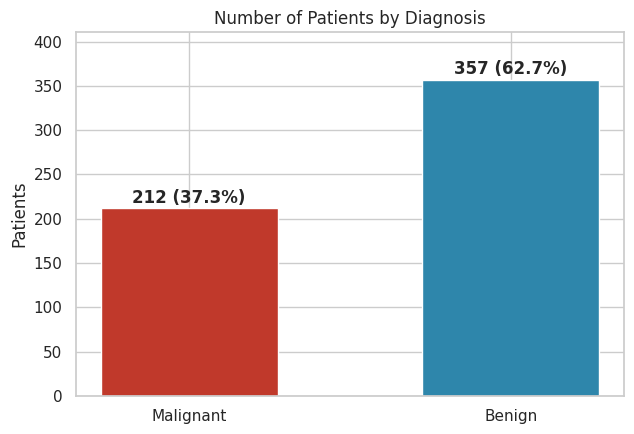

In [24]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
cnt = df["diagnosis"].value_counts().reindex(ORDER)
bars = ax.bar(cnt.index, cnt.values, color=[PAL[k] for k in cnt.index], width=0.55)
for b, val in zip(bars, cnt.values):
    ax.text(b.get_x() + b.get_width() / 2, val + 6, f"{val} ({val / len(df) * 100:.1f}%)", ha="center", fontweight="bold")
ax.set(title="Number of Patients by Diagnosis", ylabel="Patients", xlabel="", ylim=(0, cnt.max() * 1.15))
save_fig("01_bar_diagnosis_counts")
plt.show()

**Observation.** The dataset contains **357 benign** and **212 malignant** patients (about **1.7 benign cases for every malignant one**). The imbalance is moderate: not large enough to ruin an analysis, but large enough that **accuracy alone would be misleading** (always guessing "benign" would already be 62.7% accurate). This is why recall and AUC are reported in Section 4.5.

### Chart 2 – Histogram with density curve: mean radius by diagnosis

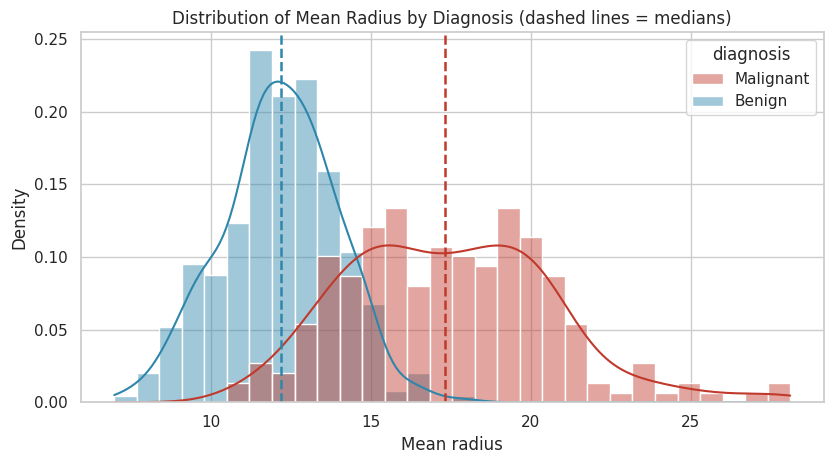

In [25]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.histplot(data=df, x="mean_radius", hue="diagnosis", hue_order=ORDER, palette=PAL, kde=True,
             stat="density", common_norm=False, bins=30, alpha=0.45, ax=ax)
for k in ORDER:
    ax.axvline(df.loc[df["diagnosis"] == k, "mean_radius"].median(), color=PAL[k], linestyle="--", linewidth=1.8)
ax.set(title="Distribution of Mean Radius by Diagnosis (dashed lines = medians)", xlabel="Mean radius", ylabel="Density")
save_fig("02_hist_mean_radius")
plt.show()

**Observation.** The two distributions are clearly shifted: the median mean radius is **17.3 for malignant** and **12.2 for benign** tumours. The benign curve is narrow and sits to the left, while the malignant curve is wider (standard deviation 3.20 versus 1.78) and extends far to the right. The two curves **overlap in the middle** (roughly 12 to 16), which is where a single measurement is ambiguous. Normalizing each group to its own density (`common_norm=False`) makes the shapes comparable despite the different group sizes.

### Chart 3 – Histogram grid: six mean features by diagnosis

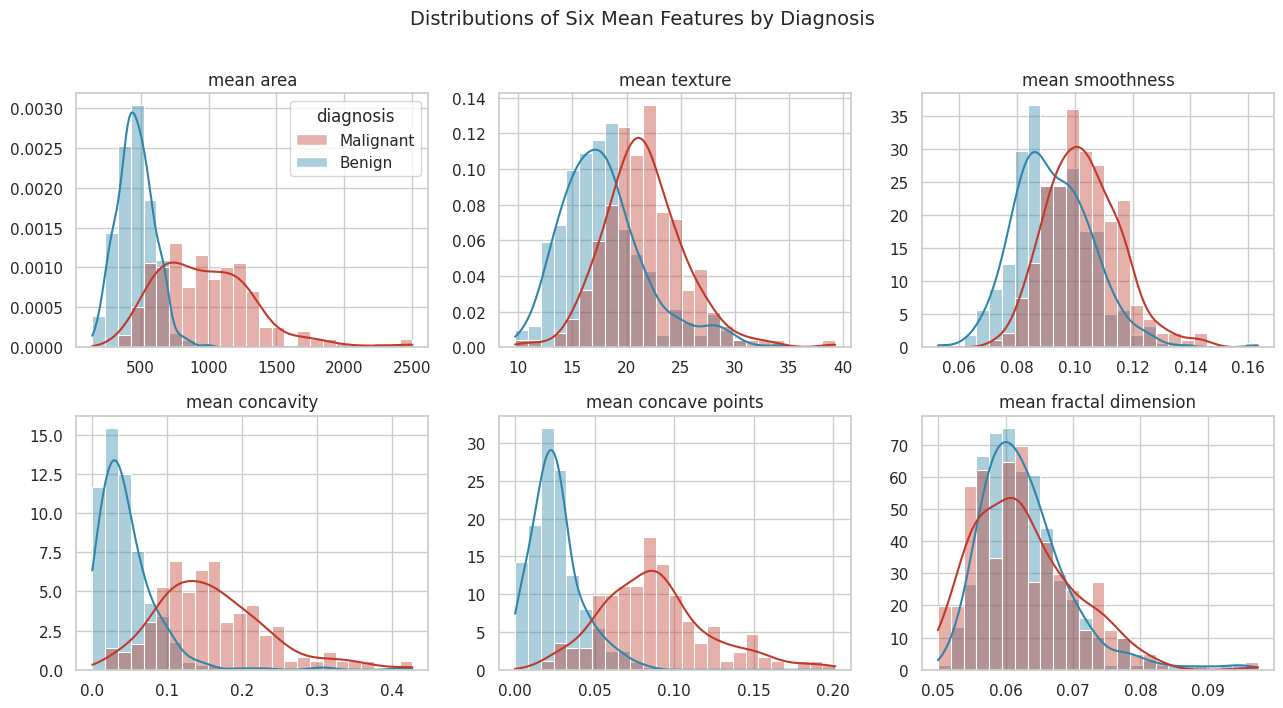

In [26]:
six = ["mean_area", "mean_texture", "mean_smoothness", "mean_concavity", "mean_concave_points", "mean_fractal_dimension"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, f in zip(axes.ravel(), six):
    sns.histplot(data=df, x=f, hue="diagnosis", hue_order=ORDER, palette=PAL, kde=True, stat="density",
                 common_norm=False, bins=25, alpha=0.4, legend=(f == six[0]), ax=ax)
    ax.set(title=f.replace("_", " "), xlabel="", ylabel="")
fig.suptitle("Distributions of Six Mean Features by Diagnosis", fontsize=14, y=1.01)
save_fig("03_hist_grid_six_features")
plt.show()

**Observation.** The six panels show a spectrum of usefulness. **`mean_area`, `mean_concavity` and `mean_concave_points`** show a clear malignant shift to the right with a long right tail. **`mean_texture` and `mean_smoothness`** are shifted only moderately and overlap heavily: their effect sizes (d = 0.94 and 0.79) are large by the usual convention but less than half the d of about 2.7 of the best feature. **`mean_fractal_dimension`** is almost identical for both groups (d = -0.03). Seeing the distributions, not just the averages, shows *why* some features are strong and others weak: it is the amount of overlap.

### Chart 4 – Box plots: strong and weak features side by side

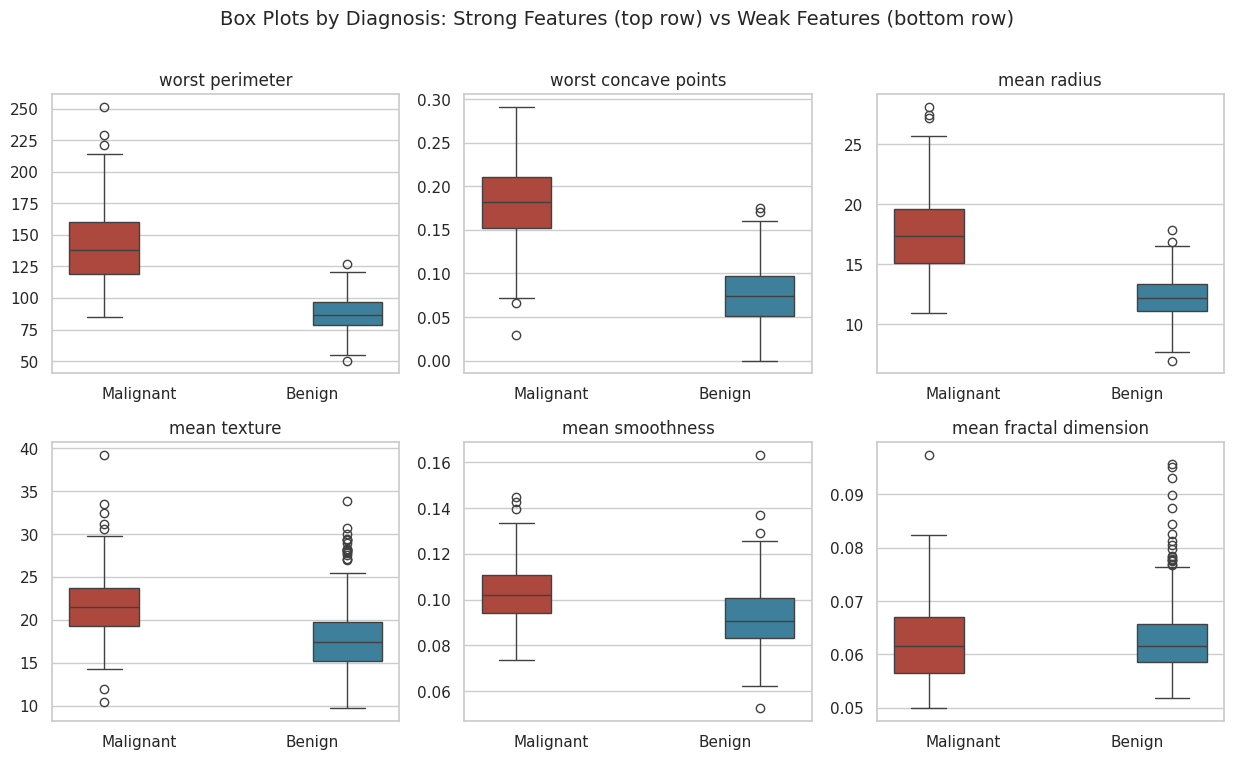

In [27]:
six_box = ["worst_perimeter", "worst_concave_points", "mean_radius", "mean_texture", "mean_smoothness", "mean_fractal_dimension"]
fig, axes = plt.subplots(2, 3, figsize=(12.5, 7.5))
for ax, f in zip(axes.ravel(), six_box):
    sns.boxplot(data=df, x="diagnosis", y=f, hue="diagnosis", order=ORDER, hue_order=ORDER, palette=PAL, legend=False, ax=ax)
    ax.set(title=f.replace("_", " "), xlabel="", ylabel="")
fig.suptitle("Box Plots by Diagnosis: Strong Features (top row) vs Weak Features (bottom row)", fontsize=14, y=1.01)
save_fig("04_box_grid_strong_vs_weak")
plt.show()

**Observation.** In the top-row features (`worst_perimeter`, `worst_concave_points`, `mean_radius`) the **boxes barely overlap**: the typical (median) malignant value is above the entire middle half of the benign values. In `mean_texture` and `mean_smoothness` the boxes overlap substantially, although the malignant median is still higher, and in `mean_fractal_dimension` the two boxes are almost identical. The malignant boxes are also taller, meaning malignant tumours are **more variable**, and the dots beyond the whiskers (individual outliers) are mostly in the malignant group for the size features, which matches the outlier finding in Section 3.4.

### Chart 5 – Violin plot: the six strongest features on a common scale
Standardized values (z-scores) put features with different units on one axis.

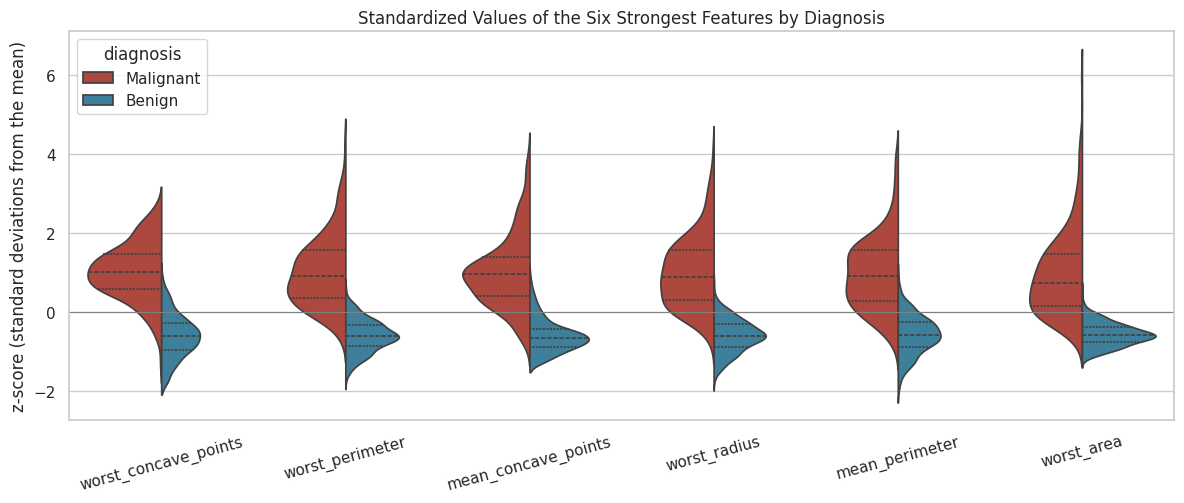

In [28]:
top6 = effects.index[:6].tolist()
long = X_scaled[top6].assign(diagnosis=df["diagnosis"].astype(str).values).melt(id_vars="diagnosis", var_name="feature", value_name="z_score")
fig, ax = plt.subplots(figsize=(12, 5.2))
sns.violinplot(data=long, x="feature", y="z_score", hue="diagnosis", hue_order=ORDER, palette=PAL, split=True, inner="quart", ax=ax)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set(title="Standardized Values of the Six Strongest Features by Diagnosis", xlabel="", ylabel="z-score (standard deviations from the mean)")
ax.tick_params(axis="x", rotation=15)
save_fig("05_violin_top6_features")
plt.show()

**Observation.** Each violin is split: the red half shows malignant values and the blue half benign values. For every one of the six features, the malignant half sits **about one to two standard deviations above zero** while the benign half sits below it, and the two halves overlap only in their tails. The six strongest features are `worst_concave_points, worst_perimeter, mean_concave_points, worst_radius, mean_perimeter, worst_area`; four of the six are size measures and two are boundary-irregularity measures, so **size and irregularity together carry the diagnostic signal**.

### Chart 6 – Scatter plot: two size measures (a picture of redundancy)

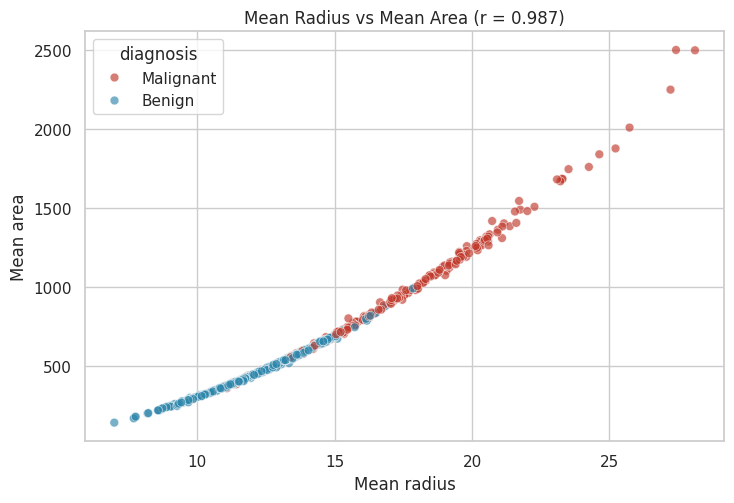

In [29]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
sns.scatterplot(data=df, x="mean_radius", y="mean_area", hue="diagnosis", hue_order=ORDER, palette=PAL, alpha=0.65, s=40, ax=ax)
ax.set(title=f"Mean Radius vs Mean Area (r = {df['mean_radius'].corr(df['mean_area']):.3f})", xlabel="Mean radius", ylabel="Mean area")
save_fig("06_scatter_radius_vs_area")
plt.show()

**Observation.** The points trace one smooth curve, as area grows with the square of the radius, so knowing one gives the other almost exactly (Pearson r = 0.987). This is the visual form of the redundancy that justified reducing the feature set. The classes are also visible: **benign points (blue) cluster at the lower left and malignant points (red) dominate the upper right**, with a mixed band in between.

### Chart 7 – Scatter plot: a size-independent pair of features

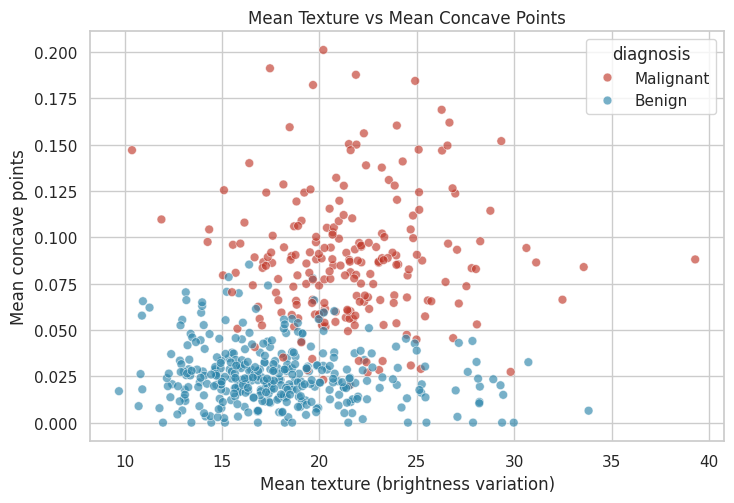

In [30]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
sns.scatterplot(data=df, x="mean_texture", y="mean_concave_points", hue="diagnosis", hue_order=ORDER, palette=PAL, alpha=0.65, s=40, ax=ax)
ax.set(title="Mean Texture vs Mean Concave Points", xlabel="Mean texture (brightness variation)", ylabel="Mean concave points")
save_fig("07_scatter_texture_vs_concave_points")
plt.show()

**Observation.** Using two features that are **not redundant** (r = 0.29) separates the groups better than either alone: the benign points lie low across the whole texture range, while the malignant points rise high on the concave-points axis, with a tendency to higher texture as well. The upper right is almost entirely malignant. Combining complementary features is why multi-feature models beat single-feature ones.

### Chart 8 – Pair plot: four features at once

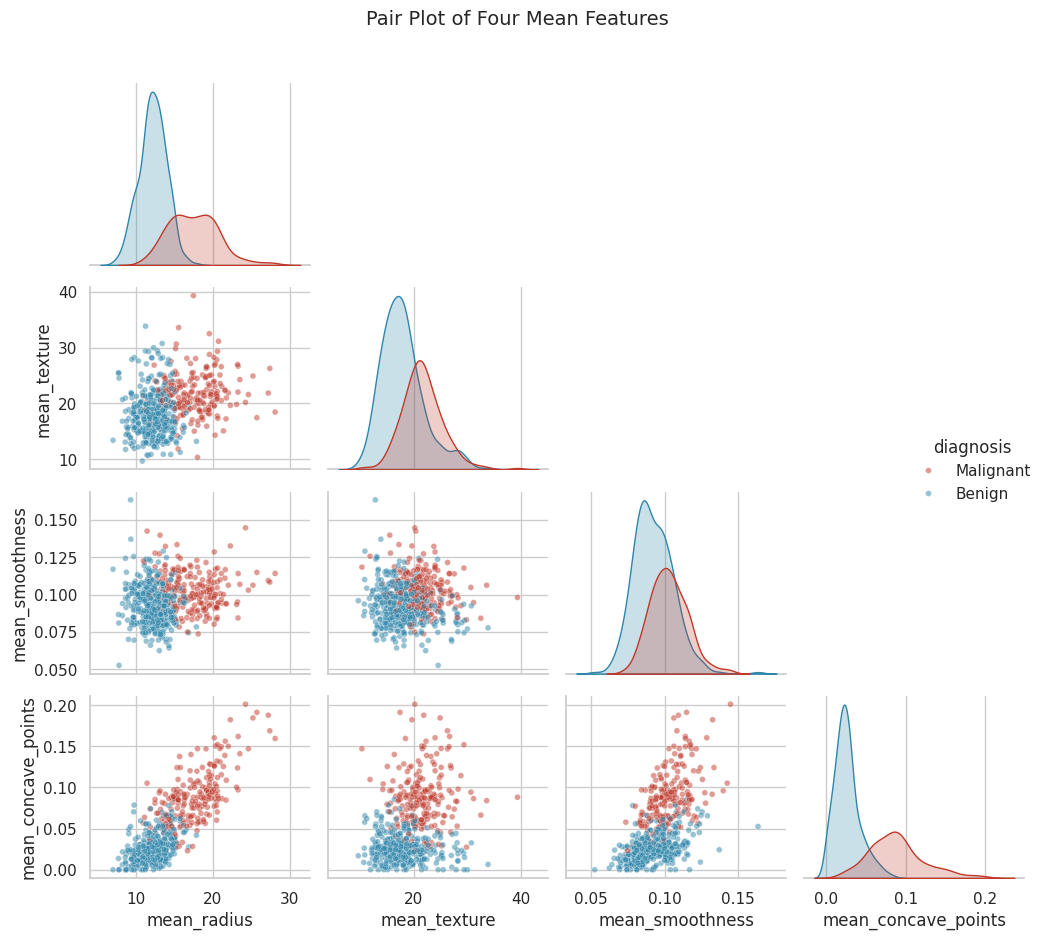

In [31]:
grid = sns.pairplot(df, vars=["mean_radius", "mean_texture", "mean_smoothness", "mean_concave_points"], hue="diagnosis", hue_order=ORDER,
                    palette=PAL, corner=True, height=2.3, plot_kws={"alpha": 0.5, "s": 18})
grid.figure.suptitle("Pair Plot of Four Mean Features", y=1.02, fontsize=14)
save_fig("08_pairplot_four_features")
plt.show()

**Observation.** The diagonal panels show each feature's distribution by class (the same overlap pattern as Chart 3), and the off-diagonal panels show every pairwise relationship in one view. The `mean_radius` and `mean_concave_points` pair gives the cleanest class separation, texture and smoothness add complementary but weaker information, and the **positive link between radius and concave points** (larger tumours also have more irregular outlines) is visible. A pair plot is a fast way to screen many relationships before choosing which to examine closely.

### Chart 9 – Heat map: correlations between the ten mean features

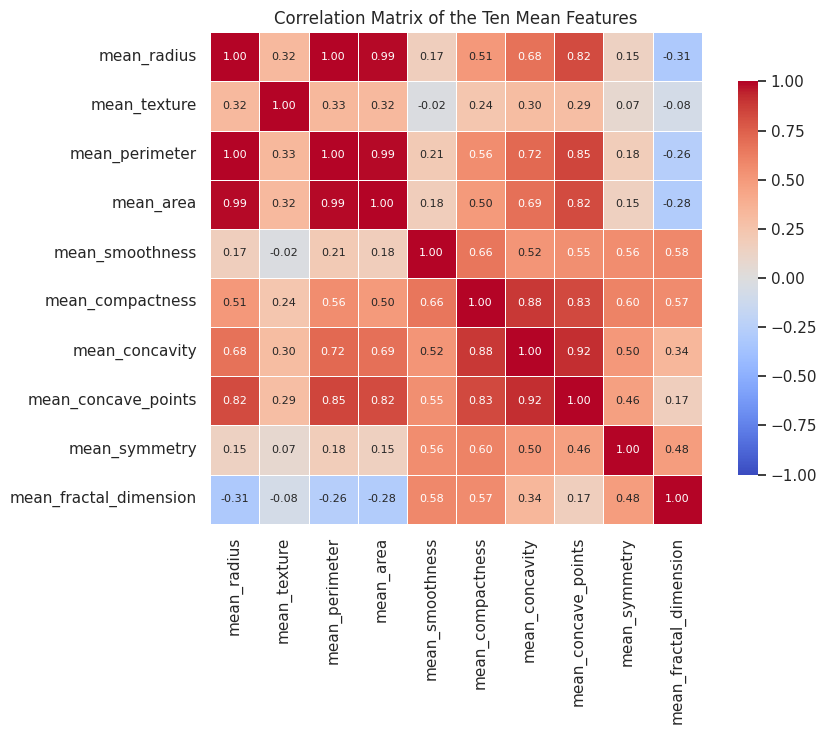

In [32]:
fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(df[MEAN].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.4, cbar_kws={"shrink": 0.8}, annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation Matrix of the Ten Mean Features")
save_fig("09_heatmap_mean_features")
plt.show()

**Observation.** Two dark-red blocks stand out: the **size block** (radius, perimeter, area; r above 0.98) and the **irregularity block** (compactness, concavity, concave points; r from 0.83 to 0.92). `mean_texture` is a lightly coloured row, meaning it is largely independent of the others, and `mean_fractal_dimension` is even negatively related to size (r = -0.31). Heat maps make this block structure visible instantly, which a table of 45 correlation values cannot.

### Chart 10 – Bar chart: correlation of each feature with malignancy

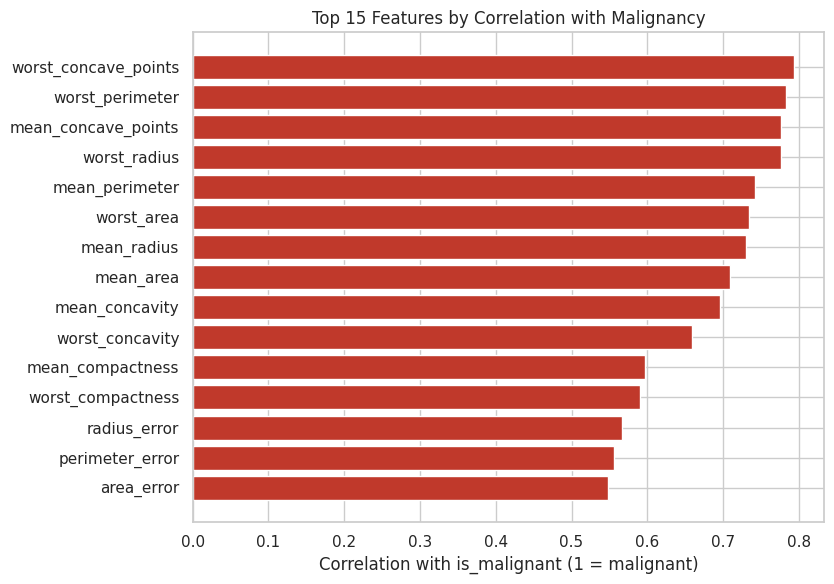

In [33]:
corr_target = df[FEATURES].corrwith(df["is_malignant"]).sort_values(key=abs, ascending=False).head(15).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(corr_target.index, corr_target.values, color=[PAL["Malignant"] if r > 0 else PAL["Benign"] for r in corr_target.values])
ax.set(title="Top 15 Features by Correlation with Malignancy", xlabel="Correlation with is_malignant (1 = malignant)", ylabel="")
save_fig("10_bar_corr_with_malignancy")
plt.show()

**Observation.** All fifteen strongest correlations are **positive** (malignancy rises with the feature), and they are led by `worst_concave_points` (r = 0.79), `worst_perimeter` (0.78) and `mean_concave_points` (0.78). The fifteen are split evenly between `worst_` summaries (6) and `mean_` summaries (6), plus 3 `_error` summaries (area_error, perimeter_error, radius_error), which are all size-related. Because of the 0 = malignant coding in the raw data, the same chart built on the raw `target` would have **all signs reversed**, which is why the recoding in Section 3 matters.

### Chart 11 – Bar chart: effect size (Cohen's d) of the strongest features

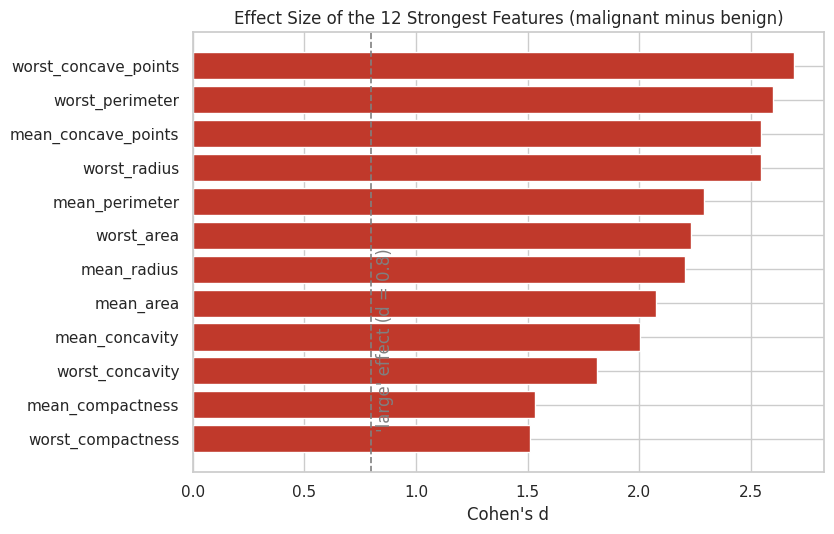

In [34]:
top12 = effects.head(12).sort_values("cohens_d")
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(top12.index, top12["cohens_d"], color=PAL["Malignant"])
ax.axvline(0.8, color="grey", linestyle="--", linewidth=1.2)
ax.text(0.82, 0.2, "'large' effect (d = 0.8)", rotation=90, va="bottom", color="grey")
ax.set(title="Effect Size of the 12 Strongest Features (malignant minus benign)", xlabel="Cohen's d", ylabel="")
save_fig("11_bar_cohens_d")
plt.show()

**Observation.** Every one of the twelve strongest features is at least **1.9 times** the conventional "large effect" threshold of 0.8 (the weakest of the twelve has d = 1.51). Effect-size charts complement correlation charts: correlation measures the *linear association*, whereas Cohen's d measures *how many standard deviations apart* the group averages are, which is easier to explain to a non-technical audience.

### Chart 12 – Line chart: the malignant rate across ten size bands

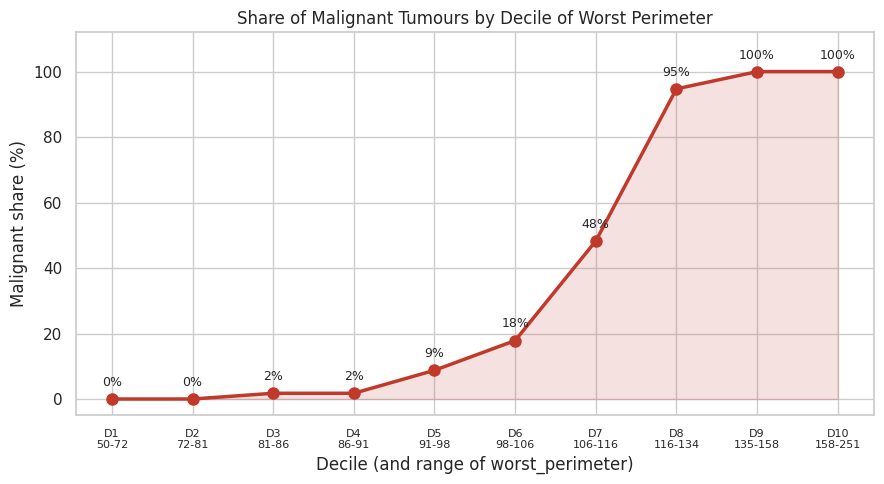

In [35]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(trend))
ax.plot(x, trend["malignant_rate_pct"], marker="o", markersize=8, linewidth=2.5, color=PAL["Malignant"])
ax.fill_between(x, trend["malignant_rate_pct"], alpha=0.15, color=PAL["Malignant"])
for xi, val in zip(x, trend["malignant_rate_pct"]):
    ax.text(xi, val + 4, f"{val:.0f}%", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([f"{lab}\n{lo:.0f}-{hi:.0f}" for lab, lo, hi in zip(trend.index, trend["min_worst_perimeter"], trend["max_worst_perimeter"])], fontsize=8)
ax.set(title="Share of Malignant Tumours by Decile of Worst Perimeter", xlabel="Decile (and range of worst_perimeter)", ylabel="Malignant share (%)", ylim=(-5, 112))
save_fig("12_line_malignant_rate_by_decile")
plt.show()

**Observation.** The malignant share forms a clear **S-shaped (sigmoid) curve**: essentially flat near 0% for the smallest tumours, a steep rise through the middle deciles, and a plateau near 100% at the top. The steepest step is between deciles 7 and 8 (a jump of 46 percentage points), where `worst_perimeter` is roughly 116. This is exactly the shape that logistic regression models, which explains why it performed so well in Section 4.5. Labelling the actual perimeter range under each decile keeps the chart interpretable.

### Chart 13 – Stacked bar chart: where are the outliers?

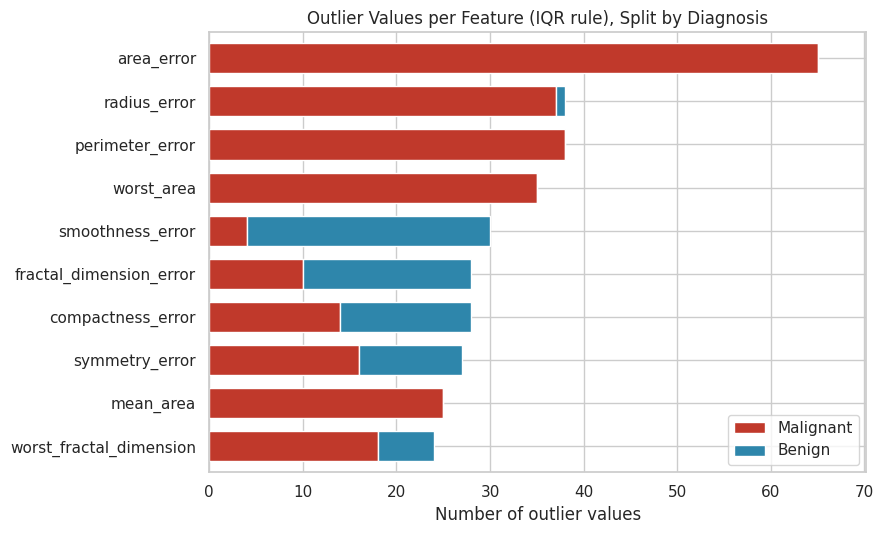

In [36]:
top_out = outlier_summary.head(10).index
is_m = df["is_malignant"] == 1
out_counts = pd.DataFrame({
    "Malignant": [int((out_mask[c] & is_m).sum()) for c in top_out],
    "Benign":    [int((out_mask[c] & ~is_m).sum()) for c in top_out],
}, index=top_out).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5.5))
out_counts.plot(kind="barh", stacked=True, color=[PAL["Malignant"], PAL["Benign"]], ax=ax, width=0.7)
ax.set(title="Outlier Values per Feature (IQR rule), Split by Diagnosis", xlabel="Number of outlier values", ylabel="", xlim=(0, out_counts.sum(axis=1).max() * 1.08))
save_fig("13_stacked_outliers_by_diagnosis")
plt.show()

**Observation.** For the features with the most outliers (`area_error`, `radius_error`, `perimeter_error`, `worst_area`) the bars are **entirely or almost entirely red**: these outliers are malignant tumours with unusually large measurements. In contrast, for features such as `smoothness_error` the outliers are mostly **blue (benign)**. So outliers are not one phenomenon: in size-related features they mark the abnormal malignant cases, in other features they are ordinary variation among benign tumours. This chart is the visual evidence for the decision to **keep** the outliers.

### Chart 14 – Line and scatter plots: how much information is in the 30 features?

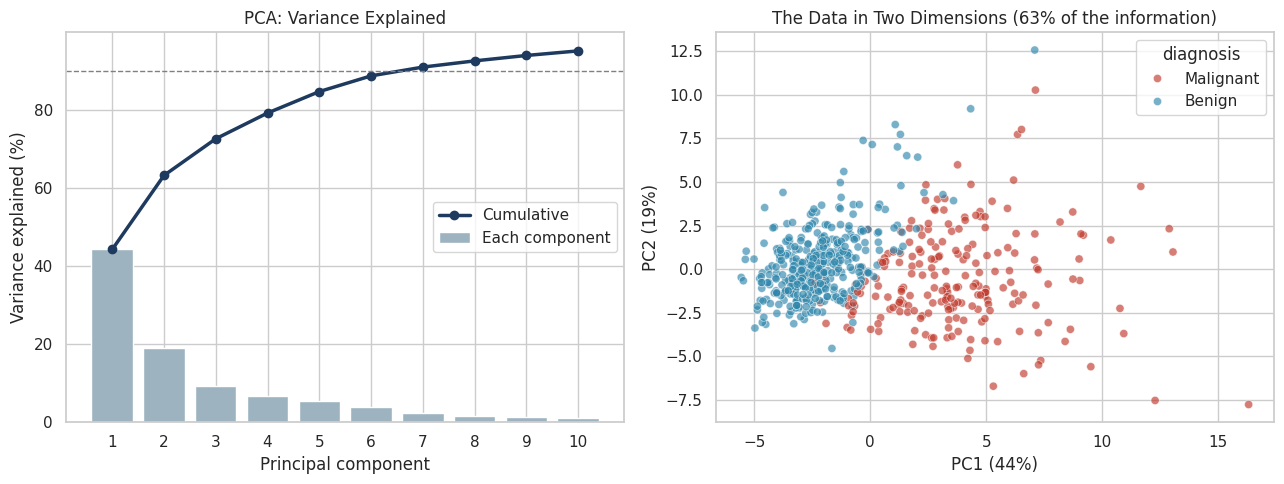

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
k = np.arange(1, 11)
axes[0].bar(k, evr[:10] * 100, color="#9DB4C0", label="Each component")
axes[0].plot(k, cum[:10] * 100, marker="o", color="#1F3A5F", linewidth=2.5, label="Cumulative")
axes[0].axhline(90, color="grey", linestyle="--", linewidth=1)
axes[0].set(title="PCA: Variance Explained", xlabel="Principal component", ylabel="Variance explained (%)", xticks=k)
axes[0].legend(loc="center right")
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="diagnosis", hue_order=ORDER, palette=PAL, alpha=0.65, s=35, ax=axes[1])
axes[1].set(title=f"The Data in Two Dimensions ({cum[1] * 100:.0f}% of the information)", xlabel=f"PC1 ({evr[0] * 100:.0f}%)", ylabel=f"PC2 ({evr[1] * 100:.0f}%)")
save_fig("14_pca_variance_and_scatter")
plt.show()

**Observation.** On the left, the cumulative line crosses the 90% mark at **component 7**, so **7 dimensions** are enough to describe the information in 30 features. On the right, squeezing all 30 features into **just two dimensions** (which keep 63% of the information) already produces two clouds: malignant tumours (red) on the right of PC1 and benign (blue) on the other side, with a modest overlap in the middle. The separation happens along PC1, the direction of greatest variation, which was computed *without ever seeing the diagnosis*.

### Chart 15 – Confusion matrix and ROC curve of the hold-out test

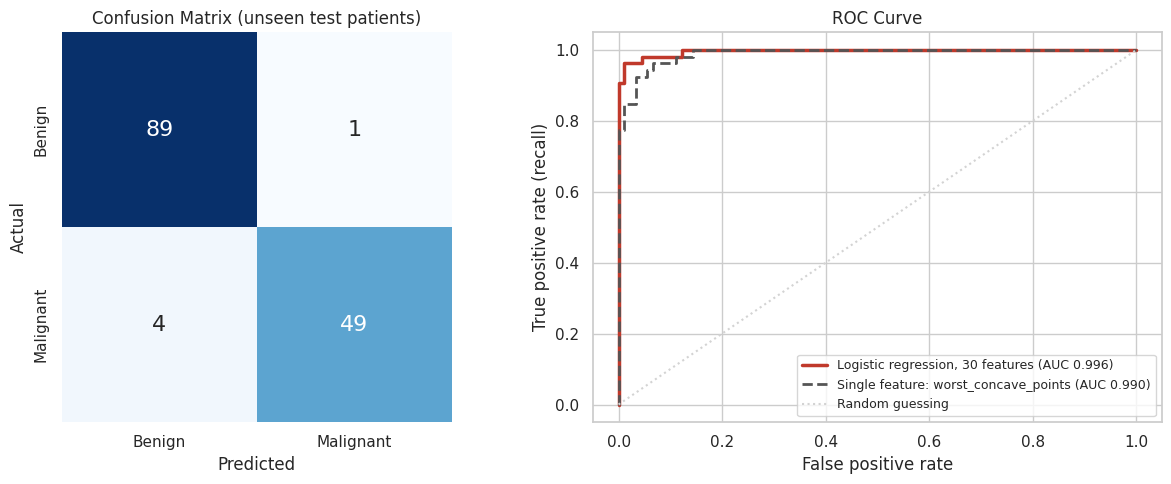

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True, annot_kws={"size": 16},
            xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"], ax=axes[0])
axes[0].set(title="Confusion Matrix (unseen test patients)", xlabel="Predicted", ylabel="Actual")

fpr, tpr, _ = roc_curve(y_te, proba)
axes[1].plot(fpr, tpr, linewidth=2.5, color=PAL["Malignant"], label=f"Logistic regression, 30 features (AUC {roc_auc_score(y_te, proba):.3f})")
f1 = best1
fpr1, tpr1, _ = roc_curve(y_te, X_te[f1])
auc1 = roc_auc_score(y_te, X_te[f1])
if auc1 < 0.5:
    fpr1, tpr1, _ = roc_curve(y_te, -X_te[f1]); auc1 = 1 - auc1
axes[1].plot(fpr1, tpr1, linewidth=2, linestyle="--", color="#555555", label=f"Single feature: {f1} (AUC {auc1:.3f})")
axes[1].plot([0, 1], [0, 1], color="lightgrey", linestyle=":", label="Random guessing")
axes[1].set(title="ROC Curve", xlabel="False positive rate", ylabel="True positive rate (recall)")
axes[1].legend(loc="lower right", fontsize=9)
save_fig("15_confusion_matrix_and_roc")
plt.show()

**Observation.** The confusion matrix shows that, among the 143 unseen test patients, **138 were classified correctly**; **4 malignant tumours were missed** (bottom left) and **1 benign tumour was wrongly flagged** (top right). The ROC curve hugs the top-left corner, with AUC 0.996 for the full model, and even the single best feature comes close (0.990). In a screening setting the decision threshold can be moved to catch more malignant cases at the cost of more false alarms, and the ROC curve shows that trade-off.

---
# 6. Insights, Interpretations and Recommendations

## 6.1 Key findings

In [39]:
findings = pd.DataFrame([
    ("Class balance",        f"{int(cnt['Benign'])} benign ({cnt['Benign'] / len(df) * 100:.1f}%) vs {int(cnt['Malignant'])} malignant ({cnt['Malignant'] / len(df) * 100:.1f}%)", "Moderate imbalance; accuracy alone is misleading"),
    ("Data quality",         "0 missing, 0 duplicates, correct types; 13 meaningful zeros", "Curated source; zeros are genuine (all benign)"),
    ("Strongest features",   f"{effects.index[0]} (d = {effects['cohens_d'].iloc[0]:.2f}), {effects.index[1]} ({effects['cohens_d'].iloc[1]:.2f}), {effects.index[2]} ({effects['cohens_d'].iloc[2]:.2f})", "Malignant averages are 2+ standard deviations higher"),
    ("Breadth of the effect",f"{int((effects['abs_d'] >= 0.8).sum())} of 30 features have a large effect; {int(effects['significant'].sum())} significant (Bonferroni)", "The difference is systematic, not a single-feature fluke"),
    ("Weak features",        f"{', '.join(effects.sort_values('abs_d').index[:3])} (|d| <= {effects.sort_values('abs_d')['abs_d'].iloc[2]:.2f})", "Carry almost no diagnostic information"),
    ("Redundancy",           f"{len(high)} pairs with |r| > 0.90; radius vs perimeter r = {df['mean_radius'].corr(df['mean_perimeter']):.3f}", f"{len(REDUCED)} features give about the same accuracy as all 30"),
    ("Outliers",             f"{int(any_outlier.sum())} rows ({any_outlier.mean() * 100:.0f}%) flagged; size outliers 97-100% malignant", "Real abnormal tumours; removal would bias results"),
    ("Size-malignancy trend",f"Malignant rate rises from {trend['malignant_rate_pct'].iloc[0]:.0f}% to {trend['malignant_rate_pct'].iloc[-1]:.0f}% across worst_perimeter deciles", f"Diagnosis is truly mixed only in {mixed_n} patients ({mixed_n / len(df) * 100:.1f}%), where worst_perimeter is {mixed_lo:.0f}-{mixed_hi:.0f}"),
    ("Predictive check",     f"CV accuracy {cv_table.iloc[0]['accuracy'] * 100:.1f}%, recall {cv_table.iloc[0]['recall'] * 100:.1f}%, AUC {cv_table.iloc[0]['roc_auc']:.3f}", "Measurements separate the classes very well"),
    ("Dimensionality",       f"{n90} PCA components keep 90% of the variance; PC1 = {evr[0] * 100:.0f}%", "30 features hold far less independent information"),
], columns=["Topic", "Finding", "Meaning"])
findings

,Topic,Finding,Meaning
0,Class balance,357 benign (62.7%) vs 212 malignant (37.3%),Moderate imbalance; accuracy alone is misleading
1,Data quality,"0 missing, 0 duplicates, correct types; 13 mea...",Curated source; zeros are genuine (all benign)
2,Strongest features,"worst_concave_points (d = 2.69), worst_perimet...",Malignant averages are 2+ standard deviations ...
3,Breadth of the effect,20 of 30 features have a large effect; 26 sign...,"The difference is systematic, not a single-fea..."
4,Weak features,"symmetry_error, texture_error, mean_fractal_di...",Carry almost no diagnostic information
5,Redundancy,21 pairs with |r| > 0.90; radius vs perimeter ...,21 features give about the same accuracy as al...
6,Outliers,171 rows (30%) flagged; size outliers 97-100% ...,Real abnormal tumours; removal would bias results
7,Size-malignancy trend,Malignant rate rises from 0% to 100% across wo...,Diagnosis is truly mixed only in 114 patients ...
8,Predictive check,"CV accuracy 97.4%, recall 94.4%, AUC 0.995",Measurements separate the classes very well
9,Dimensionality,7 PCA components keep 90% of the variance; PC1...,30 features hold far less independent information


## 6.2 Interpretation: answers to the research questions
| Question | Answer from the analysis |
|---|---|
| **1. How balanced are the classes?** | Moderately imbalanced: 357 benign vs 212 malignant (37.3% malignant). |
| **2. Which measurements differ most, and by how much?** | Concave points, perimeter, radius and area (worst and mean forms). Their group means are 2 to 2.7 standard deviations apart. Texture, smoothness and fractal dimension differ little. |
| **3. How are the measurements related?** | They form two redundant blocks: size (r above 0.98) and boundary irregularity (r 0.83 to 0.92). Texture is largely independent. 21 features carry about the same predictive information as all 30. |
| **4. Are there outliers, and should they be removed?** | Yes (30% of patients have at least one), but they should be **kept**: in the size features they are almost all malignant tumours, i.e. real signal. |
| **5. How well do the measurements separate the classes?** | Very well: about 97% cross-validated accuracy and 94% recall for malignant cases with a simple, interpretable model. |

## 6.3 Were the hypotheses supported?
| Hypothesis | Verdict | Evidence |
|---|---|---|
| **H1:** malignant nuclei are larger | **Supported** | `mean_radius` d = 2.21, `mean_area` d = 2.08 |
| **H2:** malignant nuclei have more irregular boundaries | **Supported** | `mean_concave_points` d = 2.55, `mean_concavity` d = 2.00 |
| **H3:** size measurements are almost perfectly correlated | **Supported** | radius vs perimeter r = 0.998; radius vs area r = 0.987 |

One result was **not anticipated**: the *worst* (most extreme nuclei) summary is stronger than the *mean* summary for **8 of the 10 characteristics** (for example `perimeter`: d = 2.60 vs 2.29), so the most abnormal nuclei in a sample tell more than the average nucleus. In addition, a few features (such as `mean_fractal_dimension`) turned out to be nearly useless.

## 6.4 Limitations
- **Curated, single-source data.** Records come from one research group in the 1990s; the results may not carry over to other hospitals, equipment or populations.
- **Pre-computed features, not images.** Only the summary measurements are available, so it is impossible to examine the raw images or verify the measurement process.
- **No patient context.** There is no age, history or other clinical information, so effects cannot be adjusted for other factors.
- **Association is not causation.** The analysis shows that larger, more irregular nuclei go *with* malignancy; it does not explain biological mechanisms.
- **Multiple testing and optimistic estimates.** 30 features were tested (Bonferroni was applied). Cross-validated performance on a clean research dataset is likely higher than performance in real clinical use.
- **Not a diagnostic tool.** The model is for learning only; real diagnosis requires a pathologist and further tests, and the cost of a missed cancer is far greater than that of a false alarm.

## 6.5 Recommendations
**For further analysis**
1. Use the **reduced feature set** (or PCA) to avoid redundancy, and report **recall and AUC**, not accuracy alone, because the classes are imbalanced and a missed malignant case is the costly error.
2. Validate any model on **external data** from a different source before drawing conclusions.
3. Try interpretable alternatives (decision trees, regularized regression) and calibrate the decision threshold to favour recall.

**For practice (if this were a real project)**
4. Treat model output as a **second opinion that prioritizes cases for expert review**, never as a final diagnosis.
5. Where a single measurement is ambiguous (the overlap zone), combine several features and always escalate to human review.

**For data collection**
6. Add patient context (age, history), multi-site samples and ethically approved image access so that findings can be checked more thoroughly.

## 6.6 Conclusion
The analysis shows that the cell-nucleus measurements in the Wisconsin Diagnostic Breast Cancer dataset describe a **clear, systematic, and measurable difference between malignant and benign tumours**: malignant nuclei are larger and have more irregular outlines, by more than two standard deviations on the best features. The 30 measurements are highly redundant (about 7 principal components, or 21 low-redundancy features, carry almost all of the information), outliers are real abnormal cases rather than errors, and a simple model separates the classes very well on unseen data. The honest caveats are that the data is curated and from a single source, so the results illustrate what is *measurable* in this dataset and not how a tool would perform in a clinic.

## 6.7 Objectives checklist
| # | Objective | Status | Evidence |
|---|---|---|---|
| 1 | Select a real-world dataset and understand its context | Done | Section 1: UCI source, selection criteria, variables, objectives, hypotheses |
| 2 | Explore the dataset | Done | Section 2: structure, types, distributions, missing values, duplicates, geometry check, first relationships |
| 3 | Clean and preprocess the data | Done | Section 3: renaming, label recoding, zeros, outliers, skewness, redundancy, scaling, validation, decision log |
| 4 | Perform exploratory data analysis | Done | Section 4: group comparison, effect sizes, tests, correlations, trends, predictive check, PCA |
| 5 | Create data visualizations | Done | Section 5: 15 charts saved in `outputs/figures/` |
| 6 | Present insights and interpretations | Done | Section 6: findings, answers, hypotheses, limitations, recommendations, conclusion |

## 6.8 Reproducibility
Fixed random seed (`SEED = 42`), relative paths, raw data kept unmodified in `data/raw/`, cleaned data in `data/processed/`, validation by `assert` statements, and a `requirements.txt`. To reproduce: install the requirements, open the notebook and choose **Kernel → Restart & Run All**.

**Data source and reference:** Wolberg, W.H., Street, W.N. and Mangasarian, O.L., *Breast Cancer Wisconsin (Diagnostic)*, UCI Machine Learning Repository; Street, W.N., Wolberg, W.H. and Mangasarian, O.L. (1993), *Nuclear feature extraction for breast tumor diagnosis*, IS&T/SPIE International Symposium on Electronic Imaging, vol. 1905, pp. 861-870.

In [40]:
# Collect the headline numbers (used to cross-check the written report)
facts = {
    "n_patients": int(len(df)), "n_malignant": int(mal.shape[0]), "n_benign": int(ben.shape[0]),
    "pct_malignant": round(float(df["is_malignant"].mean() * 100), 1),
    "rows_with_zero": int(rows_with_zero.sum()),
    "outlier_values": int(out_mask.sum().sum()), "outlier_rows": int(any_outlier.sum()),
    "outlier_rows_pct": round(float(any_outlier.mean() * 100), 1),
    "outlier_rows_malignant_pct": round(float(df.loc[any_outlier, "is_malignant"].mean() * 100), 1),
    "skewed_before": int(len(skewed)), "skewed_after": int((df_log[FEATURES].skew().abs() > 1).sum()),
    "pairs_over_090": int(len(high)), "reduced_n": int(len(REDUCED)),
    "top_feature": effects.index[0], "top_d": round(float(effects["cohens_d"].iloc[0]), 2),
    "large_effect_n": int((effects["abs_d"] >= 0.8).sum()), "significant_n": int(effects["significant"].sum()),
    "best_single_auc": round(float(effects["auc"].max()), 3),
    "cv_all": {k: round(float(v), 3) for k, v in cv_table.iloc[0].items()},
    "cv_reduced": {k: round(float(v), 3) for k, v in cv_table.iloc[1].items()},
    "cv_top3": {k: round(float(v), 3) for k, v in cv_table.iloc[2].items()},
    "cv_best1": {k: round(float(v), 3) for k, v in cv_table.iloc[3].items()},
    "holdout": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp), "auc": round(float(roc_auc_score(y_te, proba)), 3)},
    "pca_pc1_pct": round(float(evr[0] * 100), 1), "pca_first2_pct": round(float(cum[1] * 100), 1), "pca_n90": n90,
    "trend_first": round(float(trend["malignant_rate_pct"].iloc[0]), 1), "trend_last": round(float(trend["malignant_rate_pct"].iloc[-1]), 1),
    "overlap_n": overlap_n, "overlap_pct": round(overlap_n / len(df) * 100, 1),
    "mixed_n": mixed_n, "mixed_pct": round(mixed_n / len(df) * 100, 1), "mixed_lo": round(float(mixed_lo), 0), "mixed_hi": round(float(mixed_hi), 0),
    "irr_min": round(float(irr.min()), 2), "irr_max": round(float(irr.max()), 2),
    "radius_perimeter_r": round(float(df["mean_radius"].corr(df["mean_perimeter"])), 3),
}
print(pd.Series({k: v for k, v in facts.items() if not isinstance(v, dict)}).to_string())

n_patients                                     569
n_malignant                                    212
n_benign                                       357
pct_malignant                                 37.3
rows_with_zero                                  13
outlier_values                                 608
outlier_rows                                   171
outlier_rows_pct                              30.1
outlier_rows_malignant_pct                    66.7
skewed_before                                   22
skewed_after                                    15
pairs_over_090                                  21
reduced_n                                       21
top_feature                   worst_concave_points
top_d                                         2.69
large_effect_n                                  20
significant_n                                   26
best_single_auc                              0.975
pca_pc1_pct                                   44.3
pca_first2_pct                 